# Replicação e melhoria do *Fast Genetic Algorithm for Feature Selection* (census-income)

**Disciplina:** IA Avançada (UNICAP) · **Artigo:** Altarabichi, Nowaczyk, Pashami & Mashhadi, *Expert Systems with Applications* 211 (2023) 118528 · [arXiv:2404.03996](https://arxiv.org/pdf/2404.03996) · **Código oficial:** [Ghaith81/Fast-Genetic-Algorithm-For-Feature-Selection](https://github.com/Ghaith81/Fast-Genetic-Algorithm-For-Feature-Selection)

Este notebook contém **todo o trabalho em um só lugar**, em duas partes que seguem a tarefa da disciplina:

| Parte | Tarefa | Pergunta que responde |
|---|---|---|
| **A — Replicação** | Reproduzir exatamente o artigo com o código oficial | *Conseguimos obter os mesmos números da Tabela 2 do artigo?* |
| **B — Melhoria** | Propor e implementar uma melhoria, na mesma base | *É possível melhorar o resultado onde o artigo reconhece uma limitação?* |
| **C — Resumo para o relatório** | Respostas diretas ao roteiro da disciplina | *O que escrever no relatório e nos slides?* |

## Como o projeto está organizado

```
Fast-Genetic-Algorithm-For-Feature-Selection-main/
├── projeto_original/            ← o projeto dos AUTORES (só 3 correções de compatibilidade)
│   ├── code/                    Dataset.py, Evolution.py, Example.ipynb
│   ├── data/census-income.data
│   └── results/results.csv
└── nossa_replica/               ← o NOSSO trabalho
    ├── projeto_replica_e_melhoria.ipynb   (este notebook)
    ├── melhoria/DatasetMod.py   a única mudança de lógica da melhoria
    ├── src/                     runner.py (executa as buscas) e analise.py (tabelas/gráficos)
    ├── results/                 runs/*.json (1 por execução) e os CSVs finais
    ├── figures/                 PNGs 150 dpi para os slides
    └── README.md
```

A regra que organiza tudo: **nada em `projeto_original/` muda a lógica dos autores**. A melhoria vive inteira em `nossa_replica/`, numa subclasse.

## Mapa do notebook

| Seção | O que faz | Por que está aqui |
|---|---|---|
| A1–A2 | Explica o problema, o artigo e os 4 algoritmos | Contexto para julgar a replicação |
| A3 | Setup, sementes, correções de compatibilidade | Reprodutibilidade e transparência |
| A4 | Análise exploratória | Descobre o desbalanceamento |
| A5 | Baselines (DT completa e classe majoritária) | Régua de comparação |
| A6 | Roda os 4 algoritmos × `N_RUNS` | Gera os dados da replicação |
| A7 | Tabela 2 vs artigo | Critério de sucesso da replicação |
| A8 | Gráficos | Qualidade, tempo e atributos escolhidos |
| A9 | Divergências artigo × código | Honestidade metodológica |
| A10 | Limitações observadas | **Ponte para a melhoria** |
| A11 | Salva resultados | Insumo do relatório |
| B1 | Motivação da melhoria | Por que mexer |
| B2 | A melhoria em palavras simples + implementação | O que muda e o que não muda |
| B3–B4 | Resultados e testes estatísticos | Quanto melhora, e se é consistente |
| B5 | Gráficos | Trade-off visível |
| B6 | Ablações, MCC e coluna 24 | Isola o efeito de cada ingrediente |
| B7 | Transferência para outros classificadores | A seleção generaliza além da árvore? |
| B8 | Discussão e recomendação | Conclusão |
| C | Resumo para o relatório | Roteiro da disciplina |

## Como executar (e quanto demora)

* Rode o notebook **a partir da pasta `nossa_replica/`**.
* `N_RUNS` (padrão 10) controla as repetições; `N_RUNS=1` é o **modo rápido** para validar o pipeline. Variáveis de ambiente opcionais: `N_RUNS`, `N_RUNS_CHC`, `RODAR_M3`, `RODAR_ABLACOES`, `RODAR_EXTRA` (0/1) e `EXECUTAR` (0 = só lê resultados já salvos, sem rodar buscas).
* Cada execução é gravada em `results/runs/` ao terminar; se o kernel cair, reexecute as células — só o que falta é refeito.
* Tempo aproximado com 8 processos: Parte A ≈ 10–15 min; Parte B ≈ 1–1,5 h sem M3 e ≈ 3 h com M3 (SMOTE). Detalhes no `README.md`.

---
# PARTE A — Replicação do artigo

Objetivo: **replicar exatamente** o experimento na base census-income, com o código dos autores e sem alterar sua lógica, e depois examinar criticamente os resultados.

## A1. O problema e a ideia do artigo

> 🎯 **O que esta seção faz:** Apresenta o problema (seleção de atributos), a ideia do artigo (aproximação qualitativa, QX) e a lógica geral.
>
> 💡 **Por que existe:** Sem entender *o que* o artigo propõe, não dá para julgar se a replicação foi fiel nem onde a melhoria se encaixa.

**Seleção de atributos (*feature selection*) por *wrapper*.** Dada uma base com 41 atributos, queremos o subconjunto que maximiza o desempenho de um classificador (aqui, uma Árvore de Decisão). Um *wrapper* avalia cada subconjunto candidato **treinando o classificador** — preciso, porém caro: com 41 atributos há $2^{41}$ subconjuntos e cada avaliação treina um modelo com ~120 mil instâncias.

**Algoritmos genéticos / enxames.** Em vez de testar todos, uma meta-heurística evolui uma população de subconjuntos (vetores binários de 41 posições: 1 = atributo selecionado). Cada indivíduo precisa de uma avaliação de *fitness*, e isso domina o tempo de execução.

**A ideia do artigo — aproximação qualitativa (QX).** Treinar com **menos instâncias** é mais barato, e o valor absoluto da acurácia muda, mas o que a busca realmente precisa é do **ranking** dos subconjuntos (qual é melhor que qual). Então:

1. Sorteia-se um conjunto de `q` subconjuntos de atributos aleatórios e avalia-se cada um com a **função original** (treino completo).
2. Busca-se uma **amostra de instâncias** tal que o modelo treinado nela produza um ranking *parecido* com o original. A semelhança é medida pela **correlação de postos de Spearman** entre as acurácias aproximadas e as originais; a amostra também é penalizada pelo tempo que gasta (`distância = (1 − ρ) + tempo_aprox / tempo_original`).
3. O **meta-modelo** (treino na amostra escolhida) passa a ser a fitness do algoritmo evolutivo.
4. Como a aproximação pode errar, há **controle de evolução**: a cada `f` gerações os melhores indivíduos são reavaliados com a função original; a busca só termina após `f_no_change` rodadas sem melhoria.

## A2. Os quatro algoritmos comparados

> 🎯 **O que esta seção faz:** Lista os quatro algoritmos e os hiperparâmetros exatos do notebook oficial.
>
> 💡 **Por que existe:** Replicar "exatamente" exige fixar cada valor; qualquer diferença contaminaria a comparação com o artigo.

| Algoritmo | O que é | Parâmetros no notebook oficial |
|---|---|---|
| **CHC_QX** | CHC (algoritmo genético com seleção elitista, cruzamento HUX e reinício por *cataclysmic mutation*) + meta-modelo QX | `f=10`, `q=10`, `f_no_change=2`, população 50 |
| **PSO_QX** | PSO (enxame de partículas, topologia estrela) + meta-modelo QX | `f=10`, `q=10`, `f_no_change=2`, 50 partículas |
| **CHC** | CHC puro, fitness com função original | população 50, `d = k//4`, `max_no_change=10` |
| **PSO** | PSO puro, fitness com função original | 50 partículas, `steps_no_change=10` |

Em todos, **a fitness é a acurácia no conjunto de validação**; o resultado final é reportado como **acurácia no conjunto de teste**. O teste nunca participa da busca.

## A3. Instalação e importações

> 🎯 **O que esta seção faz:** Importa bibliotecas, fixa threads e sementes, define `N_RUNS`/`N_JOBS` e documenta as 3 correções de compatibilidade.
>
> 💡 **Por que existe:** Reprodutibilidade (sementes), comparação justa de tempo (1 thread por processo) e transparência sobre o que foi mexido no código dos autores.

Dependências: `deap`, `pyswarms`, `scikit-learn`, `pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `joblib` (e `imbalanced-learn` para o Parte B). Veja o `README.md` para o passo a passo (local e Colab).

### Correções de compatibilidade (as **únicas** alterações no código dos autores)

O código foi escrito em 2022 e quebra com numpy 2 / pandas recentes. Foram feitas exatamente três correções, **sem tocar na lógica**:

| Arquivo | Original | Corrigido | Por quê |
|---|---|---|---|
| `projeto_original/code/Dataset.py` | `np.NaN` | `np.nan` | `np.NaN` foi removido no numpy 2 |
| `projeto_original/code/Dataset.py` | `pd.read_csv(..., delim_whitespace=True, ...)` | `pd.read_csv(..., sep=r"\s+", ...)` | `delim_whitespace` foi descontinuado no pandas. Esse ramo **não é usado** pelo census-income (que é separado por vírgula) |
| `projeto_original/code/Example.ipynb` | `np.warnings.filterwarnings(...)` | linha removida | `np.warnings` não existe mais; a linha apenas silenciava um aviso |

`projeto_original/code/Evolution.py` **não foi alterado**.

### Reprodutibilidade e paralelismo

* **Sementes:** cada execução `s ∈ {0,…,9}` chama `random.seed(s)` e `np.random.seed(s)` (o `pyswarms` usa `np.random`). Assim, cada execução é determinística.
* **`OMP_NUM_THREADS=1`:** cada processo usa uma única thread; o paralelismo vem de rodar execuções independentes em processos separados (`joblib`). Isso também mantém a medição de tempo comparável entre execuções.
* **Retomada:** cada execução é gravada em `results/runs/*.json` assim que termina. Se o kernel cair, basta reexecutar a célula — só o que falta é refeito.

In [1]:
import os, sys, warnings
for v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[v] = '1'          # uma thread por processo (ver explicação acima)
warnings.filterwarnings('ignore')

from pathlib import Path
RAIZ = Path.cwd()                                   # pasta nossa_replica/ (rode o notebook a partir dela)
if RAIZ.name != 'nossa_replica' and (RAIZ / 'nossa_replica').exists():
    RAIZ = RAIZ / 'nossa_replica'
ORIGINAL = RAIZ.parent / 'projeto_original'          # código e dados dos autores
sys.path.insert(0, str(RAIZ / 'src')); sys.path.insert(0, str(ORIGINAL / 'code')); sys.path.insert(0, str(RAIZ / 'melhoria'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, f1_score, precision_score

import runner                      # executor (src/runner.py): 1 execução = (config, algoritmo, semente)
from analise import *              # tabelas, testes, paleta e salvar_fig
from Dataset import Dataset        # código ORIGINAL dos autores

# ------------------------- PARÂMETROS -------------------------
N_RUNS = int(os.environ.get('N_RUNS', 10))   # nº de repetições por algoritmo (artigo: 10). Use 1 para teste rápido.
N_JOBS = int(os.environ.get('N_JOBS', max(1, min(8, (os.cpu_count() or 2) - 1))))   # processos em paralelo
SEEDS = list(range(N_RUNS))
# --------------------------------------------------------------
print(f'N_RUNS={N_RUNS}  N_JOBS={N_JOBS}  sementes={SEEDS}')

N_RUNS=10  N_JOBS=8  sementes=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## A4. Análise exploratória da base

> 🎯 **O que esta seção faz:** Mede dimensões, valores faltantes, distribuição de classes e a proporção de positivos em treino/validação/teste.
>
> 💡 **Por que existe:** Conhecer a base antes de modelar. O **desbalanceamento** descoberto aqui é a base de toda a Parte B.

A base census-income (UCI, *Census-Income KDD*) tem como tarefa prever se a renda anual de uma pessoa **excede US$ 50 mil**. O arquivo já vem **numérico e codificado** (sem cabeçalho); o código dos autores aplica `LabelEncoder` a colunas textuais (não há nenhuma aqui) e preenche faltantes pela mediana (também não há). A **última coluna (índice 41) é o rótulo**.

**Divisão 60/20/20 sem embaralhar.** `Dataset.divide_dataset` usa os primeiros 60 % das linhas para treino, os 20 % seguintes para validação e os 20 % finais para teste, **na ordem do arquivo** (`shuffle=False`). A normalização *z-score* usa média e desvio **só do treino**, evitando vazamento de informação. Convém verificar se a proporção da classe positiva se mantém nas três partes, já que a divisão não é estratificada.

Dimensões: (199523, 42) (linhas × colunas, incluindo o rótulo)
Valores faltantes: 0 | tipos: [dtype('int64') dtype('float64')]


,instâncias,positivos (renda > 50K),% positivos,% classe majoritária
treino (60%),119713.0,7358.0,6.15,93.85
validação (20%),39905.0,2510.0,6.29,93.71
teste (20%),39905.0,2514.0,6.30,93.70
base toda,199523.0,12382.0,6.21,93.79


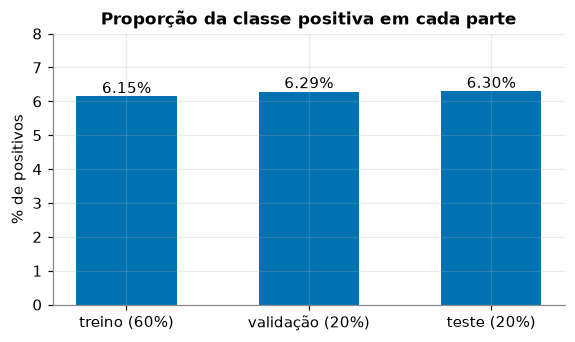

In [2]:
dados = pd.read_csv(ORIGINAL / 'data' / 'census-income.data', header=None)
y = dados.iloc[:, -1].values
print('Dimensões:', dados.shape, '(linhas × colunas, incluindo o rótulo)')
print('Valores faltantes:', int(dados.isna().sum().sum()), '| tipos:', dados.dtypes.unique())

n = len(dados); i1, i2 = int(.6 * n), int(.8 * n)
partes = {'treino (60%)': y[:i1], 'validação (20%)': y[i1:i2], 'teste (20%)': y[i2:], 'base toda': y}
tab = pd.DataFrame({k: {'instâncias': len(v), 'positivos (renda > 50K)': int(v.sum()),
                        '% positivos': round(100 * v.mean(), 2), '% classe majoritária': round(100 * (1 - v.mean()), 2)}
                    for k, v in partes.items()}).T
display(tab)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(list(partes)[:3], [100 * v.mean() for v in list(partes.values())[:3]], color=CORES['original'], width=.55)
ax.set_ylabel('% de positivos'); ax.set_title('Proporção da classe positiva em cada parte')
for i, v in enumerate(list(partes.values())[:3]): ax.text(i, 100 * v.mean() + .1, f'{100 * v.mean():.2f}%', ha='center')
ax.set_ylim(0, 8); salvar_fig(fig, 'rep_01_distribuicao_classes'); plt.show()

**Leitura.** Só ~6,2 % das instâncias são positivas: a base é **fortemente desbalanceada** (≈ 15,1 : 1). A proporção é muito parecida nas três partes, então a divisão sequencial não introduz um deslocamento relevante de classes. O desbalanceamento é a observação central deste trabalho — ele volta na seção de limitações e motiva o Parte B.

## A5. Baselines

> 🎯 **O que esta seção faz:** Calcula a Árvore de Decisão com todos os atributos e o classificador de classe majoritária no teste.
>
> 💡 **Por que existe:** A DT é o *Baseline* da Tabela 2 (checagem de que o pipeline bate com o artigo); o majoritário é a "régua de sanidade" que revela quanto a acurácia vale nesta base.

* **Árvore de Decisão com todos os atributos** (`DecisionTreeClassifier(random_state=0)`) — é o *Baseline DT* da Tabela 2 do artigo (92,87 %).
* **Classificador de classe majoritária** — um modelo "burro" que sempre responde "renda ≤ 50K". Não aprende nada, mas serve de **régua de sanidade** para qualquer acurácia nesta base.

In [3]:
clf = DecisionTreeClassifier(random_state=0)
ds = Dataset(str(ORIGINAL / 'data' / 'census-income.data'), ',', -1, divide_dataset=False, header=None)
ds.divide_dataset(clf, normalize=True, shuffle=False, all_features=True, all_instances=True,
                  evaluate=True, partial_sample=False)       # exatamente como o Example.ipynb

pred_dt = ds.clf.predict(ds.X_test)
maj = np.zeros_like(ds.y_test)                                # sempre prevê a classe 0
def resumo(y_true, y_pred):
    return {'acurácia (%)': 100 * accuracy_score(y_true, y_pred),
            'acurácia balanceada': balanced_accuracy_score(y_true, y_pred),
            'precisão': precision_score(y_true, y_pred, zero_division=0),
            'recall (classe 1)': recall_score(y_true, y_pred, zero_division=0),
            'F1 (classe 1)': f1_score(y_true, y_pred, zero_division=0)}
base = pd.DataFrame({'Árvore, todos os atributos': resumo(ds.y_test, pred_dt),
                     'Classe majoritária': resumo(ds.y_test, maj)}).T
display(base.round(4))
print(f'\nAcurácia de teste da DT (todos os atributos): {100*ds.TestAccuracy:.3f}%   | valor do artigo: 92,87%')

,acurácia (%),acurácia balanceada,precisão,recall (classe 1),F1 (classe 1)
"Árvore, todos os atributos",92.8154,0.7138,0.4348,0.4686,0.4511
Classe majoritária,93.7000,0.5000,0.0000,0.0000,0.0000



Acurácia de teste da DT (todos os atributos): 92.815%   | valor do artigo: 92,87%


**Leitura.**

* A Árvore de Decisão com todos os atributos fica **muito próxima** do valor do artigo (92,87 %). O valor que obtemos com o ambiente atual (numpy 2 / pandas 3 / scikit-learn 1.9) é conferido na célula acima; testamos as versões 1.6 a 1.9 do scikit-learn e o resultado é idêntico entre elas, então eventuais diferenças de centésimos de ponto em relação ao artigo não vêm da versão da biblioteca (provavelmente do desempate de *splits* da árvore em outro ambiente).
* A árvore completa tem acurácia baixa, mas **recall ≈ 0,47 e F1 ≈ 0,45** — bem melhor na classe de interesse do que as soluções que o GA/PSO encontram otimizando acurácia (seção A10).
* O classificador de **classe majoritária acerta ≈ 93,7 %**, ou seja, **mais que a própria árvore com todos os atributos**. Isso já indica que a acurácia, nesta base, é uma métrica enganosa: um modelo sem nenhuma capacidade preditiva "ganha" dela. O recall dele é zero — não encontra nenhum rico.

## A6. Execução dos quatro algoritmos

> 🎯 **O que esta seção faz:** Executa CHC_QX, PSO_QX, CHC e PSO `N_RUNS` vezes cada, em paralelo, gravando cada execução em `results/runs/`.
>
> 💡 **Por que existe:** Algoritmos estocásticos precisam de várias repetições (o artigo usa 10); a gravação incremental permite retomar se o kernel cair.

Cada célula abaixo roda **N_RUNS execuções por algoritmo** com os hiperparâmetros exatos do notebook oficial (ver `src/runner.py`):

```python
DecisionTreeClassifier(random_state=0)
divide_dataset(normalize=True, shuffle=False, all_features=True, all_instances=True, evaluate=True, partial_sample=False)
CHC_QX : Evolution.CHCqx(dataset, 10, 10, 2, 50)                      # f=10, q=10, f_no_change=2, população 50
PSO_QX : Evolution.PSOqx(dataset, options, 10, 10, 2, 50)             # options = {c1:1.49618, c2:1.49618, w:0.7298, k:50, p:2}
CHC    : Evolution.CHC(dataset, toolbox, d=41//4, pop50, max_no_change=10)
PSO    : Evolution.PSO(dataset, options, 50, steps_no_change=10)
```

Para cada solução final, o executor treina uma árvore com os atributos escolhidos e calcula **no teste**: acurácia, acurácia balanceada, precisão, recall, F1 (classe 1), MCC, ROC-AUC (`predict_proba`), matriz de confusão, nº de atributos, índices dos atributos e o **tempo até a melhor solução** (para os QX, inclui a construção do meta-modelo). O conjunto de teste só é usado nesta avaliação final.

> ⏱️ **Tempo.** CHC_QX e PSO_QX levam ~1 min por execução; CHC e PSO puros levam bem mais (dezenas de minutos, pois cada avaliação treina a árvore com todas as ~120 mil instâncias). Com `N_RUNS=10` e 8 processos, conte com algumas dezenas de minutos no total.

In [4]:
import time; t0 = time.time()
df = runner.run_many(['original'], runner.ALGOS, SEEDS, n_jobs=N_JOBS)
print(f'\nTempo desta célula: {(time.time()-t0)/60:.1f} min  |  execuções disponíveis: {len(df)}')
df.head()

0 execuções pendentes (de 40).

Tempo desta célula: 0.0 min  |  execuções disponíveis: 40


,config,algo,seed,n_features,features,time_best,time_total,val_accuracy,val_balanced_accuracy,val_precision,...,test_balanced_accuracy,test_precision,test_recall,test_f1,test_mcc,test_roc_auc,test_tn,test_fp,test_fn,test_tp
0,original,CHC_QX,0,6,"[12, 16, 17, 27, 28, 29]",22.729367,29.134034,0.948979,0.613006,0.851632,...,0.619001,0.841667,0.241050,0.374768,0.434429,0.759861,37277,114,1908,606
1,original,CHC_QX,1,4,"[12, 16, 17, 25]",45.296768,65.256266,0.949054,0.614346,0.848175,...,0.619928,0.836986,0.243039,0.376695,0.434862,0.762424,37272,119,1903,611
2,original,CHC_QX,2,4,"[12, 16, 17, 40]",58.393581,72.415180,0.949104,0.614002,0.852725,...,0.619624,0.844660,0.242243,0.376507,0.436408,0.761589,37279,112,1905,609
3,original,CHC_QX,3,6,"[12, 16, 17, 20, 28, 31]",44.578334,58.917693,0.949029,0.613590,0.851032,...,0.619530,0.836538,0.242243,0.375694,0.434004,0.838070,37272,119,1905,609
4,original,CHC_QX,4,5,"[12, 16, 17, 19, 25]",86.548962,104.142614,0.949104,0.615302,0.845599,...,0.620379,0.842033,0.243835,0.378162,0.437086,0.874154,37276,115,1901,613


## A7. Resultados no formato da Tabela 2 do artigo

> 🎯 **O que esta seção faz:** Monta a tabela no formato da Tabela 2 (mediana ± desvio padrão), lado a lado com o artigo e com a diferença.
>
> 💡 **Por que existe:** É o critério objetivo de sucesso da replicação.

Acurácia de teste (%), **mediana ± desvio padrão** das execuções, lado a lado com os valores do artigo e com a diferença (nossa mediana − artigo), em pontos percentuais.

In [5]:
linhas = []
baseline_pct = 100 * ds.TestAccuracy
linhas.append(['Baseline DT', f'{baseline_pct:.2f}', '92.87', f'{baseline_pct - 92.87:+.2f}', 'sim' if abs(baseline_pct - 92.87) <= 0.1 else 'não'])
for a in ['CHC', 'CHC_QX', 'PSO', 'PSO_QX']:
    s = 100 * df[df.algo == a]['test_accuracy']
    med, dp = s.median(), (s.std(ddof=1) if len(s) > 1 else np.nan)
    ref_m, ref_dp = ARTIGO[a]
    dentro = abs(med - ref_m) <= max(ref_dp, 0.1) * 1.0 + 0.1       # tolerância: 1 dp do artigo + 0,1 pp
    linhas.append([a, med_dp(df[df.algo == a]['test_accuracy']), f'{ref_m:.2f} ± {ref_dp:.2f}', f'{med - ref_m:+.2f}', 'sim' if dentro else 'não'])
tabela2 = pd.DataFrame(linhas, columns=['Algoritmo', 'Nossa replicação (mediana ± dp)', 'Artigo (mediana ± dp)', 'Δ mediana (pp)', 'Dentro da tolerância?'])
display(tabela2)
print('Execuções por algoritmo:', df.groupby('algo').size().to_dict())

,Algoritmo,Nossa replicação (mediana ± dp),Artigo (mediana ± dp),Δ mediana (pp),Dentro da tolerância?
0,Baseline DT,92.82,92.87,-0.05,sim
1,CHC,94.92 ± 0.02,94.63 ± 0.35,+0.29,sim
2,CHC_QX,94.93 ± 0.02,94.94 ± 0.07,-0.01,sim
3,PSO,94.91 ± 0.09,94.79 ± 0.24,+0.12,sim
4,PSO_QX,94.95 ± 0.05,94.94 ± 0.06,+0.01,sim


Execuções por algoritmo: {'CHC': 10, 'CHC_QX': 10, 'PSO': 10, 'PSO_QX': 10}


**Critério de sucesso adotado:** consideramos a replicação bem-sucedida para um algoritmo se a nossa mediana ficar a até **1 desvio padrão do artigo + 0,1 ponto percentual** da mediana publicada (o 0,1 pp absorve a diferença de ambiente e de geração de números aleatórios — o artigo não informa as sementes).

**Discussão.** Os resultados esperados são: (i) todos os algoritmos de seleção de atributos superam a árvore com todos os atributos em ~2 pp; (ii) as variantes **QX** igualam ou superam as puras, com **desvio padrão menor** (a busca guiada por meta-modelo é mais estável) e (iii) QX chega lá bem mais rápido (gráfico de tempo, adiante). A coluna "Dentro da tolerância?" resume quão bem a replicação reproduziu a Tabela 2; os pontos em que ela não reproduz devem ser lidos junto com a seção de divergências (seção A9).

## A8. Gráficos

> 🎯 **O que esta seção faz:** Plota a acurácia por algoritmo, o tempo até a melhor solução e a frequência de seleção de cada atributo.
>
> 💡 **Por que existe:** Mostra visualmente a qualidade (acurácia), a contribuição central do artigo (tempo) e *quais* atributos importam.

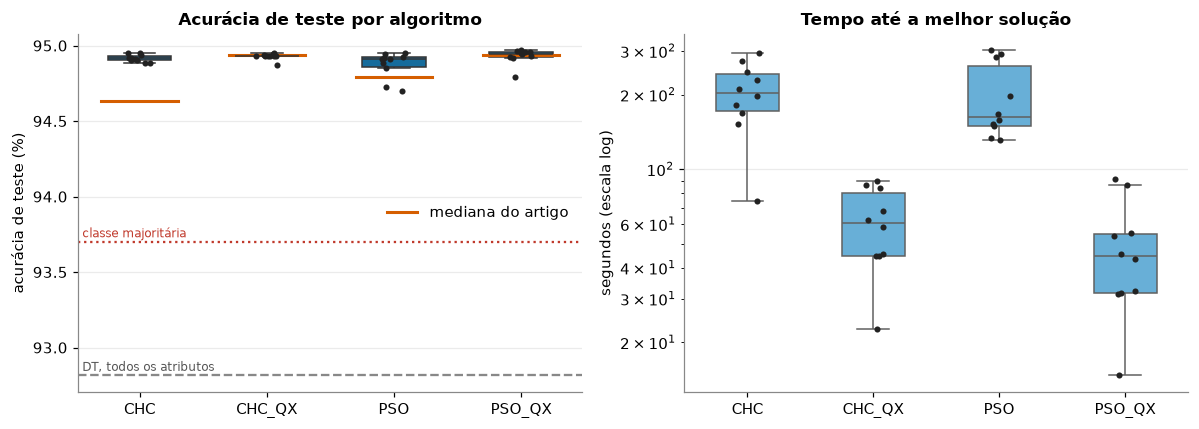

        median    min    max
algo                        
CHC      204.0   74.7  294.8
CHC_QX    60.5   22.7   89.5
PSO      162.8  130.7  301.6
PSO_QX    44.6   14.7   91.7


In [6]:
ordem = ['CHC', 'CHC_QX', 'PSO', 'PSO_QX']
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
d = df.assign(acc=100 * df.test_accuracy)
sns.boxplot(data=d, x='algo', y='acc', order=ordem, color=CORES['original'], width=.5, ax=axs[0], fliersize=0)
sns.stripplot(data=d, x='algo', y='acc', order=ordem, color='#222', size=4, ax=axs[0])
axs[0].axhline(100 * ds.TestAccuracy, ls='--', c='#888'); axs[0].text(-0.45, 100 * ds.TestAccuracy + .03, 'DT, todos os atributos', ha='left', fontsize=8, color='#555')
axs[0].axhline(100 * (1 - ds.y_test.mean()), ls=':', c='#C0392B'); axs[0].text(-0.45, 100 * (1 - ds.y_test.mean()) + .03, 'classe majoritária', ha='left', fontsize=8, color='#C0392B')
for i, a in enumerate(ordem):
    axs[0].plot([i - .3, i + .3], [ARTIGO[a][0]] * 2, c='#D55E00', lw=2, label='mediana do artigo' if i == 0 else None)
axs[0].set_xlabel(''); axs[0].set_ylabel('acurácia de teste (%)'); axs[0].set_title('Acurácia de teste por algoritmo'); axs[0].legend(loc='center right')

sns.boxplot(data=df, x='algo', y='time_best', order=ordem, color='#56B4E9', width=.5, ax=axs[1], fliersize=0)
sns.stripplot(data=df, x='algo', y='time_best', order=ordem, color='#222', size=4, ax=axs[1])
axs[1].set_yscale('log'); axs[1].set_xlabel(''); axs[1].set_ylabel('segundos (escala log)'); axs[1].set_title('Tempo até a melhor solução')
plt.tight_layout(); salvar_fig(fig, 'rep_02_acuracia_e_tempo'); plt.show()
print(df.groupby('algo')['time_best'].agg(['median', 'min', 'max']).round(1).loc[ordem])

**Leitura.** O primeiro painel compara a distribuição das acurácias com a mediana publicada (traço laranja), com a árvore completa (tracejado) e com a classe majoritária (pontilhado vermelho). O segundo mostra o ganho de tempo dos métodos QX (eixo logarítmico): é a contribuição central do artigo — **mesma qualidade, bem menos tempo**.

Em seguida, a frequência com que cada atributo é escolhido nas soluções finais. Atributos escolhidos por quase todas as execuções são os realmente informativos; os demais são ruído ou redundância.

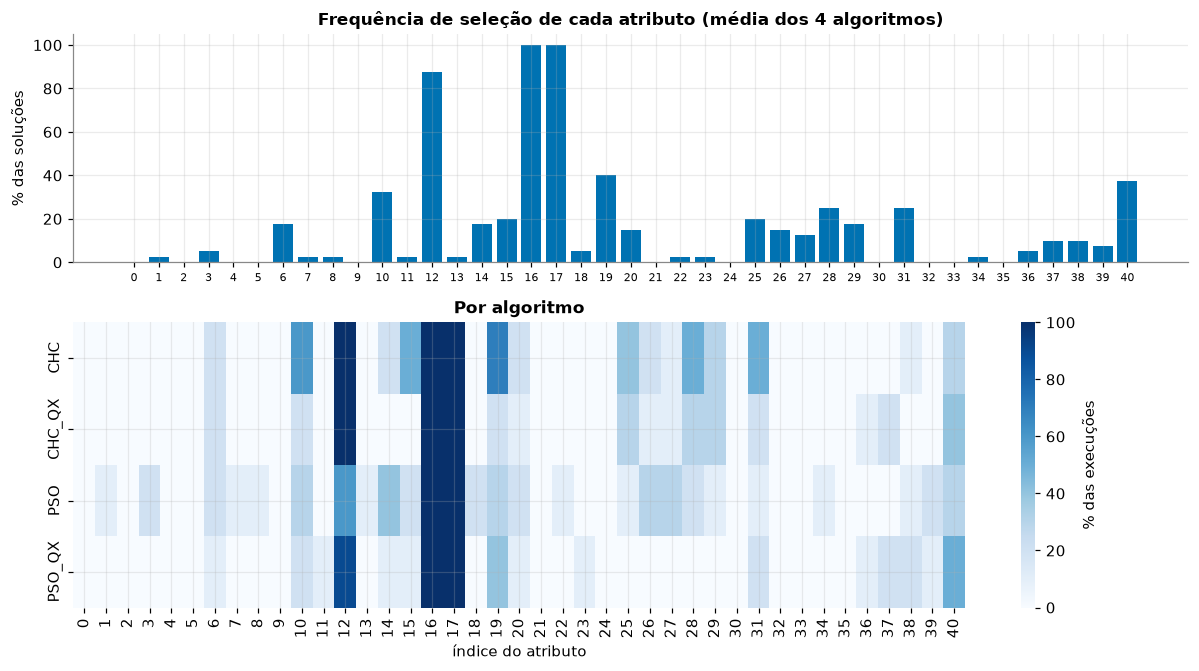

Atributos mais frequentes (índice: % das soluções): {17: 100, 16: 100, 12: 87, 19: 40, 40: 38, 10: 32, 31: 25, 28: 25}
Nº médio de atributos selecionados: {'CHC': 7.8, 'CHC_QX': 5.7, 'PSO': 6.9, 'PSO_QX': 5.4}


In [7]:
freq = np.zeros((4, 41))
for i, a in enumerate(ordem):
    sub = df[df.algo == a]
    for fs in sub['features']:
        freq[i, fs] += 1 / len(sub)
fig, axs = plt.subplots(2, 1, figsize=(11, 6.2), gridspec_kw={'height_ratios': [1, 1.25]})
geral = freq.mean(0) * 100
axs[0].bar(range(41), geral, color=CORES['original']); axs[0].set_ylabel('% das soluções'); axs[0].set_title('Frequência de seleção de cada atributo (média dos 4 algoritmos)')
axs[0].set_xticks(range(41)); axs[0].tick_params(axis='x', labelsize=7)
sns.heatmap(freq * 100, ax=axs[1], cmap='Blues', vmin=0, vmax=100, yticklabels=ordem, cbar_kws={'label': '% das execuções'})
axs[1].set_xlabel('índice do atributo'); axs[1].set_title('Por algoritmo')
plt.tight_layout(); salvar_fig(fig, 'rep_03_frequencia_atributos'); plt.show()
top = pd.Series(geral, index=range(41)).sort_values(ascending=False).head(8)
print('Atributos mais frequentes (índice: % das soluções):', {int(k): round(v) for k, v in top.items()})
print('Nº médio de atributos selecionados:', df.groupby('algo')['n_features'].mean().round(1).to_dict())

**Leitura.** Poucos atributos aparecem em quase todas as soluções e as buscas selecionam subconjuntos **bem menores que 41**. Note que a coluna **24** é o *instance weight* do UCI (peso amostral do censo), que **não deveria ser um atributo de entrada**; se ela aparece com frequência nas soluções, a árvore está se beneficiando de um atributo que, conceitualmente, não descreve a pessoa. O Parte B inclui um experimento opcional para isso.

## A9. Divergências entre o artigo e o código

> 🎯 **O que esta seção faz:** Registra onde o artigo e o código oficial divergem e o que mantivemos.
>
> 💡 **Por que existe:** Honestidade metodológica: a tarefa é replicar o código, então documentamos as diferenças em vez de "corrigi-las".

Mantivemos **o que o código faz**, pois a tarefa é replicar com o código oficial. As diferenças que identificamos:

| Item | O que diz o artigo | O que o `Example.ipynb` faz | Impacto esperado |
|---|---|---|---|
| Tamanho da amostra de subconjuntos `q` | `q = 20` | `q = 10` (`CHCqx(dataset, 10, 10, 2, 50)` — o 2º `10` é `n_individual`=q) | Meta-modelo calibrado com menos pontos → correlação de Spearman mais ruidosa, mas execução mais rápida |
| Orçamento de tempo do CHC | CHC roda pelo **mesmo tempo de CPU** que o CHC_QX | CHC para por convergência (`max_no_change=10`), sem orçamento de tempo | CHC puro leva muito mais tempo que o QX; a comparação deixa de ser "a tempo igual" |
| Embaralhamento | As instâncias são embaralhadas | `shuffle=False`: a divisão 60/20/20 segue a ordem do arquivo | Divisão determinística; se o arquivo tiver alguma ordem sistemática, treino/validação/teste podem diferir em distribuição (aqui a proporção de positivos é parecida) |

Também vale registrar: o próprio código tem outras particularidades que **não** alteramos — por exemplo, a variabilidade entre execuções vem apenas das sementes dos algoritmos (a divisão dos dados é fixa), e a busca usa a mesma validação para guiar e para escolher a melhor solução, o que favorece algum *overfitting* à validação.

## A10. Limitações observadas — por que a acurácia esconde o problema

> 🎯 **O que esta seção faz:** Calcula métricas completas das soluções replicadas (recall, F1, MCC, AUC…) e as compara com a árvore completa e com o classificador majoritário.
>
> 💡 **Por que existe:** Mostra que a acurácia alta **esconde** recall baixo — o problema que a Parte B vai atacar.

Todos os algoritmos otimizam **acurácia**. Em uma base com 93,8 % de uma única classe, maximizar acurácia empurra a busca para modelos que **quase só preveem a classe majoritária**. Verificamos isso calculando, para as soluções replicadas, as métricas completas no teste:

,acurácia,acur. balanceada,precisão,recall (cl. 1),F1 (cl. 1),MCC,ROC-AUC,nº atributos
CHC,0.949 ± 0.000,0.619 ± 0.001,0.833 ± 0.008,0.242 ± 0.001,0.375 ± 0.002,0.432 ± 0.003,0.875 ± 0.030,8.000 ± 1.687
CHC_QX,0.949 ± 0.000,0.619 ± 0.001,0.838 ± 0.006,0.242 ± 0.002,0.376 ± 0.003,0.434 ± 0.003,0.776 ± 0.049,5.500 ± 1.829
PSO,0.949 ± 0.001,0.622 ± 0.017,0.786 ± 0.058,0.247 ± 0.036,0.379 ± 0.030,0.434 ± 0.014,0.858 ± 0.069,6.500 ± 3.143
PSO_QX,0.949 ± 0.001,0.620 ± 0.001,0.844 ± 0.020,0.243 ± 0.003,0.377 ± 0.004,0.437 ± 0.007,0.870 ± 0.069,5.000 ± 1.647


Referência — classe majoritária: acurácia 0.937 | acurácia balanceada 0.500 | recall 0.000 | F1 0.000


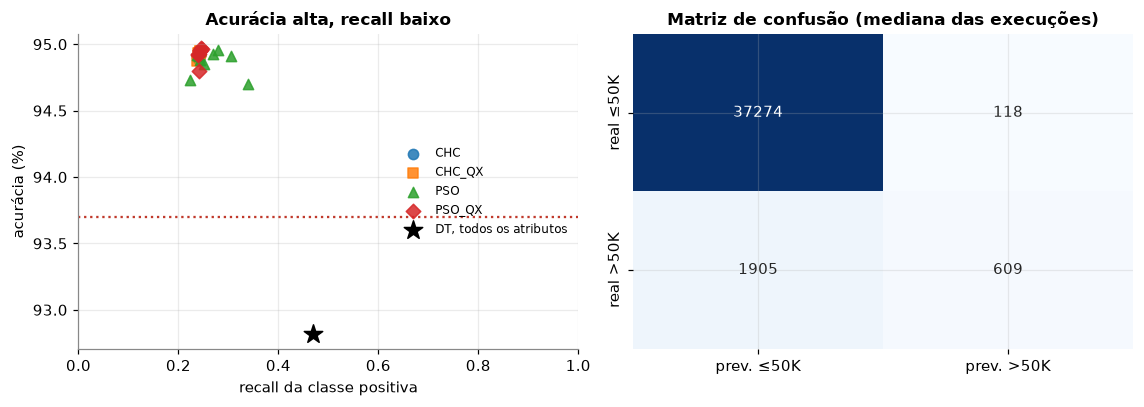

In [8]:
cols = ['test_accuracy', 'test_balanced_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_mcc', 'test_roc_auc', 'n_features']
resumo_metricas = tabela_med_dp(df, 'algo', cols,
                                escala={c: 1 for c in cols}, casas=3).loc[ordem]
resumo_metricas.columns = ['acurácia', 'acur. balanceada', 'precisão', 'recall (cl. 1)', 'F1 (cl. 1)', 'MCC', 'ROC-AUC', 'nº atributos']
display(resumo_metricas)
print('Referência — classe majoritária: acurácia 0.937 | acurácia balanceada 0.500 | recall 0.000 | F1 0.000')

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
for a, m in zip(ordem, ['o', 's', '^', 'D']):
    s = df[df.algo == a]
    axs[0].scatter(s.test_recall, 100 * s.test_accuracy, marker=m, s=45, label=a, alpha=.85)
axs[0].axhline(100 * (1 - ds.y_test.mean()), ls=':', c='#C0392B'); axs[0].set_xlabel('recall da classe positiva'); axs[0].set_ylabel('acurácia (%)')
axs[0].scatter(recall_score(ds.y_test, pred_dt), 100 * ds.TestAccuracy, marker='*', s=160, c='k', label='DT, todos os atributos')
axs[0].set_title('Acurácia alta, recall baixo'); axs[0].legend(fontsize=8, loc='center right'); axs[0].set_xlim(0, 1)
cm = np.array([[df.test_tn.median(), df.test_fp.median()], [df.test_fn.median(), df.test_tp.median()]])
sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=axs[1], xticklabels=['prev. ≤50K', 'prev. >50K'], yticklabels=['real ≤50K', 'real >50K'])
axs[1].set_title('Matriz de confusão (mediana das execuções)')
plt.tight_layout(); salvar_fig(fig, 'rep_04_acuracia_vs_recall'); plt.show()

**Leitura (o ponto central para a melhoria).**

* As soluções "boas" (~94,9 % de acurácia) ficam apenas ~1,2 pp acima do classificador que sempre responde "≤ 50K" (≈ 93,7 %).
* O **recall da classe positiva é baixo** (≈ 0,24 nas soluções replicadas): o modelo só encontra uma em cada quatro pessoas de renda alta, embora acerte a maior parte do que prevê como positivo (precisão ≈ 0,83). A acurácia balanceada fica perto de 0,62 (0,5 = chute) e o F1 da classe 1 em torno de 0,37.
* O desbalanceamento não é tratado pelo artigo — os próprios autores reconhecem isso na seção 7 (*Limitations*): *"We have never considered the class imbalance case as it is not the focus of this paper. In all experiments accuracy was used to evaluate the fitness of feature subsets. This metric could naturally be replaced with one that accounts for the imbalance case, e.g., average recall."* Eles também sugerem amostragem estratificada das instâncias do meta-modelo.
* **A busca por acurácia piorou o recall em relação à árvore com todos os atributos.** Com os 41 atributos a árvore tem recall ≈ 0,47 e F1 ≈ 0,45 (tabela da seção A5); as soluções "otimizadas" têm recall ≈ 0,24 e F1 ≈ 0,37. Elas ganham acurácia porque quase não erram a classe negativa (precisão alta, ≈ 0,83), mas deixam de encontrar metade dos positivos que a árvore completa encontrava.
* **ROC-AUC:** com poucos atributos as folhas da árvore ficam impuras, então `predict_proba` carrega alguma informação de ranking (AUC ≈ 0,67–0,88 entre execuções, com medianas por algoritmo de 0,78 a 0,88, variando bastante entre soluções com acurácia praticamente idêntica). Mesmo assim, a AUC não aparece na fitness e não corrige o limiar de decisão.

Isso define o rumo do **Parte B**: manter dados, divisão, algoritmos e hiperparâmetros, e trocar apenas a **função de fitness** (e, em variantes, o classificador/treino) para uma que enxergue a classe de interesse.

## A11. Salvando os resultados

> 🎯 **O que esta seção faz:** Grava `results/replicacao_runs.csv` e `results/replicacao_resumo.csv`.
>
> 💡 **Por que existe:** Deixa os números prontos para o relatório e os slides.

In [9]:
RES_DIR.mkdir(exist_ok=True)
saida = df.copy(); saida['features'] = saida['features'].apply(lambda f: ' '.join(map(str, f)))
saida.to_csv(RES_DIR / 'replicacao_runs.csv', index=False)

resumo_csv = pd.concat([
    tabela2.rename(columns={'Nossa replicação (mediana ± dp)': 'replicacao', 'Artigo (mediana ± dp)': 'artigo',
                            'Δ mediana (pp)': 'delta_pp', 'Dentro da tolerância?': 'dentro_tolerancia'}).set_index('Algoritmo'),
    resumo_metricas.reindex(tabela2['Algoritmo']).add_prefix('m_')], axis=1)
resumo_csv.to_csv(RES_DIR / 'replicacao_resumo.csv')
print('salvos: results/replicacao_runs.csv e results/replicacao_resumo.csv'); resumo_csv

salvos: results/replicacao_runs.csv e results/replicacao_resumo.csv


,replicacao,artigo,delta_pp,dentro_tolerancia,m_acurácia,m_acur. balanceada,m_precisão,m_recall (cl. 1),m_F1 (cl. 1),m_MCC,m_ROC-AUC,m_nº atributos
Algoritmo,,,,,,,,,,,,
Baseline DT,92.82,92.87,-0.05,sim,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CHC,94.92 ± 0.02,94.63 ± 0.35,+0.29,sim,0.949 ± 0.000,0.619 ± 0.001,0.833 ± 0.008,0.242 ± 0.001,0.375 ± 0.002,0.432 ± 0.003,0.875 ± 0.030,8.000 ± 1.687
CHC_QX,94.93 ± 0.02,94.94 ± 0.07,-0.01,sim,0.949 ± 0.000,0.619 ± 0.001,0.838 ± 0.006,0.242 ± 0.002,0.376 ± 0.003,0.434 ± 0.003,0.776 ± 0.049,5.500 ± 1.829
PSO,94.91 ± 0.09,94.79 ± 0.24,+0.12,sim,0.949 ± 0.001,0.622 ± 0.017,0.786 ± 0.058,0.247 ± 0.036,0.379 ± 0.030,0.434 ± 0.014,0.858 ± 0.069,6.500 ± 3.143
PSO_QX,94.95 ± 0.05,94.94 ± 0.06,+0.01,sim,0.949 ± 0.001,0.620 ± 0.001,0.844 ± 0.020,0.243 ± 0.003,0.377 ± 0.004,0.437 ± 0.007,0.870 ± 0.069,5.000 ± 1.647


---
# PARTE B — Melhoria: otimizar uma fitness que enxergue a classe minoritária

**Mesma base (census-income), mesma divisão 60/20/20, mesmos 4 algoritmos, mesmos hiperparâmetros** da Parte A. A única coisa que muda é *o que a busca otimiza*.

## B1. Motivação

> 🎯 **O que esta seção faz:** Resume o problema encontrado na Parte A e cita o trecho do artigo que reconhece a limitação.
>
> 💡 **Por que existe:** Toda melhoria precisa de uma motivação mensurável; aqui ela vem dos próprios dados e dos autores.

No Parte A vimos que:

* a base é **desbalanceada** (≈ 6,2 % de positivos, renda > 50K);
* um classificador que **sempre responde "≤ 50K"** já tem **≈ 93,7 %** de acurácia no teste — **mais** que a Árvore de Decisão com todos os atributos (92,87 % no artigo);
* as soluções "boas" encontradas pelo código (~94,9 %) ficam só ~1,2 pp acima disso, e com **recall da classe positiva ≈ 0,24**: encontram uma em cada quatro pessoas de renda alta, acurácia balanceada ≈ 0,62 e F1 ≈ 0,37.

Ou seja: otimizar **acurácia** recompensa modelos que ignoram a classe de interesse. Os próprios autores reconhecem a limitação na seção 7 do artigo (*Limitations*):

> *"We have never considered the class imbalance case as it is not the focus of this paper. In all experiments accuracy was used to evaluate the fitness of feature subsets. This metric could naturally be replaced with one that accounts for the imbalance case, e.g., average recall."*

Além da métrica, existe uma observação adicional que o artigo não considera: pela documentação do UCI, a **coluna 24 é o *instance weight*** (peso amostral do censo), que **não deveria ser usada como atributo de entrada**.

## B1.5 A melhoria em palavras simples

> 🎯 **O que esta seção faz:** explica a melhoria sem código, antes de entrarmos na implementação.
>
> 💡 **Por que existe:** para o grupo conseguir explicar a ideia nos slides em poucas frases.

**O problema, numa frase.** Os algoritmos do artigo escolhem atributos para *maximizar a acurácia*. Como 94 % das pessoas da base ganham até 50 mil, um modelo que quase só responde "ganha pouco" já acerta muito — e o algoritmo é **recompensado por isso**. O resultado: subconjuntos de atributos que acertam 94,9 %, mas só encontram **1 em cada 4** pessoas de renda alta (recall ≈ 0,24).

**A melhoria, numa frase.** Trocar a "nota" que a busca tenta maximizar (a *fitness*): em vez de acurácia, usar uma medida que **só dá nota alta se o modelo encontrar a classe rara** — F1 da classe positiva ou acurácia balanceada.

**Analogia.** É como avaliar um vigia de segurança só pela porcentagem de dias "sem incidente": se 94 % dos dias são tranquilos, o vigia que *nunca dispara o alarme* tira nota 94. Trocar a nota para "quantos incidentes reais ele detectou, sem alarmes falsos demais" muda quem é considerado o melhor vigia.

**Como foi implementado (e por que é elegante).** O código dos autores sempre pede a fitness por dois métodos de `Dataset` (`set_validation_accuracy` / `get_validation_accuracy`). Criamos uma **subclasse** `DatasetMod` que sobrescreve apenas esses métodos para usar outra métrica. Efeitos:

1. A fitness dos **quatro** algoritmos muda de uma só vez — sem editar `Evolution.py`.
2. O **meta-modelo do QX** também muda: ele escolhe a amostra de instâncias pela correlação de Spearman entre o ranking do meta-modelo e o ranking da função original; como a "função original" agora é F1 (ou acurácia balanceada), o meta-modelo passa a imitar *essa* métrica. Isso é coerente com a ideia central do artigo.

**As três configurações testadas**

| Config | Muda… | Intuição |
|---|---|---|
| **M1 — F1** | só a métrica de fitness | "Só vale se encontrar positivos *sem* chutar demais" |
| **M2 — acur. balanceada + `class_weight='balanced'`** | métrica **e** o treino da árvore | "Cada classe vale igual; errar um rico pesa ~15× mais" (é a sugestão dos próprios autores: *recall médio*) |
| **M3 — F1 + SMOTE** (opcional) | métrica **e** os dados de treino | "Fabrica exemplos sintéticos de ricos só no treino" |

**O que *não* muda:** base, divisão 60/20/20, normalização, classificador (árvore, `random_state=0`), algoritmos, hiperparâmetros, número de repetições, e o fato de o **teste nunca** participar da busca.

**O que esperar (o trade-off).** A acurácia **vai cair** — é inevitável, porque o original maximiza justamente ela. Em troca, recall, F1 e acurácia balanceada devem subir. A pergunta honesta não é "ficou melhor?", e sim "*a troca vale a pena para o objetivo do problema?*" — discutida na seção B8.

## B2. A modificação — isolada numa subclasse

> 🎯 **O que esta seção faz:** Implementa a mudança numa subclasse (`DatasetMod`) e define as configurações M1, M2, M3.
>
> 💡 **Por que existe:** Isolar a mudança garante que *só* a fitness muda: mesma base, divisão, algoritmos e hiperparâmetros.

`Evolution.py` **sempre** chama `set_validation_accuracy()` e `get_validation_accuracy()` para obter a fitness. Logo, basta uma subclasse de `Dataset` que sobrescreva esses métodos para mudar:

1. a **fitness dos 4 algoritmos** (CHC, PSO, CHC_QX, PSO_QX); **e**
2. o **critério do meta-modelo do QX**: `select_instances` e `evaluate_selected_instances` também leem `get_validation_accuracy()`, então a correlação de Spearman passa a ser calculada **sob a nova métrica**. Isto é coerente com o argumento do artigo (o meta-modelo deve concordar em *ranking* com a função original — agora a original é F1 ou acurácia balanceada).

**Nenhuma linha** de `Dataset.py` ou `Evolution.py` é tocada — a melhoria vive em `melhoria/DatasetMod.py`:

In [10]:
# ------------------------- PARÂMETROS DA PARTE B -------------------------
# N_RUNS (definido na Parte A) = repetições de PSO/PSO_QX. Para CHC/CHC_QX pode-se usar menos
# repetições se o tempo for curto — nesse caso, deixe isso explícito no relatório.
N_RUNS_CHC = int(os.environ.get('N_RUNS_CHC', N_RUNS))
RODAR_M3 = os.environ.get('RODAR_M3', '1') == '1'          # M3 (SMOTE) é opcional e a mais lenta
RODAR_ABLACOES = os.environ.get('RODAR_ABLACOES', '1') == '1'  # M2b, M3b, M4 (ablações e MCC)
RODAR_EXTRA = os.environ.get('RODAR_EXTRA', '1') == '1'        # experimento extra: sem a coluna 24
EXECUTAR = os.environ.get('EXECUTAR', '1') == '1'              # 0 = só lê o que já está em results/runs (não roda buscas novas)
EXECUTAR_TRANSF = os.environ.get('EXECUTAR_TRANSF', '1' if EXECUTAR else '0') == '1'   # avaliações de transferência (B7)
SEEDS_PSO, SEEDS_CHC = list(range(N_RUNS)), list(range(N_RUNS_CHC))
print(f'N_RUNS (PSO)={N_RUNS} | N_RUNS_CHC={N_RUNS_CHC} | M3={RODAR_M3} | ablações={RODAR_ABLACOES} | extra={RODAR_EXTRA} | executar={EXECUTAR}')
print('\n' + open(RAIZ / 'melhoria' / 'DatasetMod.py').read())

N_RUNS (PSO)=10 | N_RUNS_CHC=10 | M3=True | ablações=True | extra=True | executar=True

"""Melhoria proposta: troca da fitness (e, opcionalmente, do treino) isolada numa subclasse.

Nada em code/Dataset.py nem em code/Evolution.py é alterado (além das correções de
compatibilidade). Como Evolution.py sempre chama set_validation_accuracy() /
get_validation_accuracy(), sobrescrever esses métodos muda a fitness dos 4 algoritmos
E o critério do meta-modelo do QX (correlação de Spearman passa a ser calculada
sobre a nova métrica).
"""
import sys
import os
from functools import partial

import numpy as np
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef

sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath(__file__)), '..', '..', 'projeto_original', 'code'))
from Dataset import Dataset  # noqa: E402

# zero_division=0: se a árvore não prevê nenhum positivo, F1 = 0 (é o que o sklearn já
# retornaria, só que sem emitir um aviso a cada a

### Configurações comparadas (todas contra a original)

| Config | Fitness (validação) | Árvore | Ideia |
|---|---|---|---|
| `original` | acurácia | `DecisionTreeClassifier(random_state=0)` | O artigo, sem mudanças (usa a classe `Dataset` intacta) |
| `M1_f1` | **F1 da classe 1** | padrão | Troca só a métrica: média harmônica de precisão e recall da classe de interesse |
| `M2_bacc_bal` | **acurácia balanceada** (= recall médio, a sugestão dos autores) | `class_weight='balanced'` | Métrica + classificador sensível ao custo: erros na classe rara pesam ~15× mais |
| `M3_f1_smote` | F1 | padrão, treinada com **SMOTE** | Aumento de dados sintético só no treino |
| `M2b_bacc` *(ablação)* | acurácia balanceada | padrão (**sem** pesos) | Isola o efeito da métrica do efeito do `class_weight` em M2 |
| `M3b_acc_smote` *(ablação)* | **acurácia** | padrão, com **SMOTE** | Isola o efeito do SMOTE do efeito do F1 em M3 |
| `M4_mcc` *(métrica extra)* | **MCC** (Matthews) | padrão | Outra métrica balanceada, resumo único da matriz de confusão |
| `X1_acc_sem24` / `X2_f1_sem24` *(extra)* | acurácia / F1 | padrão, **sem a coluna 24** | Remove o *instance weight* (peso amostral do censo) dos atributos |

**Por que essas escolhas?**

* **F1 (M1)** foca na classe positiva e não "premia" o acerto fácil da classe majoritária. Se o modelo nunca prevê positivos, F1 = 0.
* **Acurácia balanceada (M2)** é exatamente o *recall médio* citado pelos autores. Combinamos com `class_weight='balanced'` porque o peso nas classes empurra o modelo a arriscar mais previsões positivas.
* **SMOTE (M3)** cria exemplos sintéticos da classe rara (interpolando vizinhos). É aplicado **somente no treino, depois da divisão 60/20/20 e da normalização** — validação e teste permanecem com a distribuição real, senão a avaliação seria artificial (vazamento). Ressalva: os atributos são códigos de categorias; interpolar entre códigos gera valores intermediários sem significado categórico, então o SMOTE aqui é uma aproximação.

**Por que as ablações?** M2 muda *duas* coisas ao mesmo tempo (métrica e pesos) e M3 também (métrica e SMOTE). Sem separar, não dá para saber qual ingrediente produz o efeito. `M2b` (métrica sem pesos) e `M3b` (SMOTE sem trocar a métrica) são os controles que respondem a isso.

**Regra de ouro mantida:** o conjunto de teste **nunca** é usado para escolher configuração ou hiperparâmetro. A fitness é sempre a métrica na validação; o teste só aparece na avaliação final de cada execução.

**Comparabilidade.** A configuração `original` reaproveita as mesmas execuções do Parte A (mesmos arquivos em `results/runs/`, mesmas sementes). Em cada semente, a configuração modificada começa **da mesma população inicial** que a original, o que permite testes **pareados por semente**.

In [11]:
configs = (['original', 'M1_f1', 'M2_bacc_bal'] + (['M3_f1_smote'] if RODAR_M3 else [])
           + (['M2b_bacc', 'M3b_acc_smote', 'M4_mcc'] if RODAR_ABLACOES else [])
           + (['X1_acc_sem24', 'X2_f1_sem24'] if RODAR_EXTRA else []))
import time; t0 = time.time()
partes = [runner.run_many(configs, ['PSO', 'PSO_QX'], SEEDS_PSO, n_jobs=N_JOBS, executar=EXECUTAR),
          runner.run_many(configs, ['CHC', 'CHC_QX'], SEEDS_CHC, n_jobs=N_JOBS, executar=EXECUTAR)]
df = pd.concat(partes, ignore_index=True)
print(f'Tempo desta célula: {(time.time()-t0)/60:.1f} min | execuções: {len(df)}')
print(df.groupby(['algo', 'config']).size().unstack())

0 execuções pendentes (de 180).
0 execuções pendentes (de 180).
Tempo desta célula: 0.0 min | execuções: 360
config  M1_f1  M2_bacc_bal  M2b_bacc  M3_f1_smote  M3b_acc_smote  M4_mcc  \
algo                                                                       
CHC        10           10        10           10             10      10   
CHC_QX     10           10        10           10             10      10   
PSO        10           10        10           10             10      10   
PSO_QX     10           10        10           10             10      10   

config  X1_acc_sem24  X2_f1_sem24  original  
algo                                         
CHC               10           10        10  
CHC_QX            10           10        10  
PSO               10           10        10  
PSO_QX            10           10        10  


## B3. Resultados: tabela comparativa (mediana ± desvio padrão no teste)

> 🎯 **O que esta seção faz:** Tabela com todas as métricas (mediana ± dp) por algoritmo × configuração.
>
> 💡 **Por que existe:** Permite ver, lado a lado, o que se ganha e o que se perde com cada configuração.

In [12]:
ALGS = ['PSO_QX', 'PSO', 'CHC_QX', 'CHC']
CFGS = [c for c in configs if c in df.config.unique()]
cols = ['test_accuracy', 'test_balanced_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_mcc', 'test_roc_auc', 'n_features', 'time_best']
nomes = ['acurácia (%)', 'acur. balanceada', 'precisão', 'recall', 'F1', 'MCC', 'ROC-AUC', 'nº atributos', 'tempo (s)']
esc = {c: 1 for c in cols}; esc['test_accuracy'] = 100

blocos = {}
for a in ALGS:
    sub = df[df.algo == a]
    t = tabela_med_dp(sub, 'config', cols, escala=esc, casas=3).reindex(CFGS)
    t.columns = nomes
    t['acurácia (%)'] = [med_dp(sub[sub.config == c].test_accuracy, 100, 2) for c in CFGS]
    t['nº atributos'] = [med_dp(sub[sub.config == c].n_features, 1, 1) for c in CFGS]
    t['tempo (s)'] = [med_dp(sub[sub.config == c].time_best, 1, 0) for c in CFGS]
    blocos[a] = t
    print(f'\n=== {a}  (n = {sub.groupby("config").size().to_dict()}) ===')
    display(t)
resumo = pd.concat(blocos, names=['algoritmo', 'config'])


=== PSO_QX  (n = {'M1_f1': 10, 'M2_bacc_bal': 10, 'M2b_bacc': 10, 'M3_f1_smote': 10, 'M3b_acc_smote': 10, 'M4_mcc': 10, 'X1_acc_sem24': 10, 'X2_f1_sem24': 10, 'original': 10}) ===


,acurácia (%),acur. balanceada,precisão,recall,F1,MCC,ROC-AUC,nº atributos,tempo (s)
original,94.95 ± 0.05,0.620 ± 0.001,0.844 ± 0.020,0.243 ± 0.003,0.377 ± 0.004,0.437 ± 0.007,0.870 ± 0.069,5.0 ± 1.6,45 ± 25
M1_f1,93.07 ± 0.09,0.720 ± 0.002,0.452 ± 0.006,0.480 ± 0.005,0.465 ± 0.004,0.428 ± 0.004,0.722 ± 0.003,30.5 ± 3.6,157 ± 62
M2_bacc_bal,80.92 ± 1.21,0.835 ± 0.007,0.231 ± 0.011,0.865 ± 0.010,0.364 ± 0.014,0.382 ± 0.014,0.900 ± 0.011,6.5 ± 1.4,41 ± 58
M3_f1_smote,92.14 ± 0.50,0.724 ± 0.017,0.401 ± 0.030,0.499 ± 0.034,0.446 ± 0.027,0.407 ± 0.030,0.728 ± 0.060,33.0 ± 11.3,245 ± 155
M2b_bacc,92.96 ± 0.14,0.720 ± 0.003,0.446 ± 0.009,0.480 ± 0.005,0.465 ± 0.006,0.427 ± 0.007,0.721 ± 0.003,33.0 ± 3.7,92 ± 46
M3b_acc_smote,94.65 ± 0.50,0.632 ± 0.043,0.717 ± 0.106,0.271 ± 0.094,0.394 ± 0.068,0.420 ± 0.052,0.679 ± 0.098,4.0 ± 2.3,144 ± 80
M4_mcc,93.05 ± 0.13,0.719 ± 0.005,0.451 ± 0.010,0.476 ± 0.009,0.465 ± 0.008,0.428 ± 0.009,0.720 ± 0.006,31.5 ± 4.5,128 ± 53
X1_acc_sem24,94.94 ± 0.05,0.620 ± 0.001,0.841 ± 0.019,0.242 ± 0.002,0.376 ± 0.004,0.435 ± 0.007,0.840 ± 0.060,5.0 ± 0.9,35 ± 26
X2_f1_sem24,93.06 ± 0.06,0.720 ± 0.004,0.453 ± 0.004,0.478 ± 0.009,0.467 ± 0.004,0.430 ± 0.005,0.721 ± 0.004,32.5 ± 2.4,96 ± 40



=== PSO  (n = {'M1_f1': 10, 'M2_bacc_bal': 10, 'M2b_bacc': 10, 'M3_f1_smote': 10, 'M3b_acc_smote': 10, 'M4_mcc': 10, 'X1_acc_sem24': 10, 'X2_f1_sem24': 10, 'original': 10}) ===


,acurácia (%),acur. balanceada,precisão,recall,F1,MCC,ROC-AUC,nº atributos,tempo (s)
original,94.91 ± 0.09,0.622 ± 0.017,0.786 ± 0.058,0.247 ± 0.036,0.379 ± 0.030,0.434 ± 0.014,0.858 ± 0.069,6.5 ± 3.1,163 ± 68
M1_f1,93.05 ± 0.05,0.721 ± 0.004,0.452 ± 0.004,0.481 ± 0.009,0.467 ± 0.005,0.431 ± 0.005,0.721 ± 0.004,33.0 ± 2.5,382 ± 215
M2_bacc_bal,81.01 ± 1.27,0.826 ± 0.007,0.230 ± 0.010,0.851 ± 0.019,0.362 ± 0.012,0.377 ± 0.011,0.888 ± 0.012,7.0 ± 2.1,337 ± 123
M3_f1_smote,92.07 ± 0.41,0.728 ± 0.007,0.399 ± 0.025,0.507 ± 0.011,0.446 ± 0.018,0.408 ± 0.020,0.728 ± 0.046,34.0 ± 8.0,1740 ± 670
M2b_bacc,93.07 ± 0.09,0.724 ± 0.003,0.453 ± 0.006,0.488 ± 0.006,0.471 ± 0.005,0.434 ± 0.006,0.725 ± 0.003,33.0 ± 4.8,664 ± 275
M3b_acc_smote,94.66 ± 0.33,0.632 ± 0.030,0.720 ± 0.077,0.272 ± 0.067,0.395 ± 0.051,0.422 ± 0.031,0.746 ± 0.085,4.0 ± 2.1,455 ± 158
M4_mcc,93.05 ± 0.08,0.724 ± 0.004,0.452 ± 0.006,0.486 ± 0.008,0.469 ± 0.006,0.432 ± 0.006,0.724 ± 0.004,33.0 ± 2.8,432 ± 189
X1_acc_sem24,94.87 ± 0.07,0.621 ± 0.021,0.800 ± 0.077,0.245 ± 0.046,0.377 ± 0.036,0.436 ± 0.012,0.852 ± 0.060,8.0 ± 1.9,183 ± 106
X2_f1_sem24,93.07 ± 0.06,0.725 ± 0.003,0.453 ± 0.004,0.489 ± 0.006,0.469 ± 0.004,0.432 ± 0.005,0.725 ± 0.003,35.0 ± 1.8,475 ± 184



=== CHC_QX  (n = {'M1_f1': 10, 'M2_bacc_bal': 10, 'M2b_bacc': 10, 'M3_f1_smote': 10, 'M3b_acc_smote': 10, 'M4_mcc': 10, 'X1_acc_sem24': 10, 'X2_f1_sem24': 10, 'original': 10}) ===


,acurácia (%),acur. balanceada,precisão,recall,F1,MCC,ROC-AUC,nº atributos,tempo (s)
original,94.93 ± 0.02,0.619 ± 0.001,0.838 ± 0.006,0.242 ± 0.002,0.376 ± 0.003,0.434 ± 0.003,0.776 ± 0.049,5.5 ± 1.8,60 ± 22
M1_f1,93.18 ± 0.22,0.715 ± 0.006,0.460 ± 0.017,0.468 ± 0.014,0.466 ± 0.006,0.431 ± 0.007,0.727 ± 0.011,25.5 ± 3.3,96 ± 29
M2_bacc_bal,81.67 ± 0.79,0.835 ± 0.004,0.238 ± 0.008,0.863 ± 0.007,0.372 ± 0.009,0.390 ± 0.008,0.900 ± 0.004,6.0 ± 1.4,76 ± 33
M3_f1_smote,92.57 ± 0.46,0.721 ± 0.011,0.423 ± 0.028,0.491 ± 0.021,0.449 ± 0.022,0.410 ± 0.024,0.744 ± 0.050,22.0 ± 5.8,305 ± 223
M2b_bacc,93.03 ± 0.06,0.724 ± 0.005,0.451 ± 0.004,0.487 ± 0.010,0.469 ± 0.006,0.432 ± 0.007,0.726 ± 0.005,27.5 ± 3.7,121 ± 50
M3b_acc_smote,94.33 ± 0.34,0.621 ± 0.049,0.634 ± 0.103,0.249 ± 0.108,0.370 ± 0.076,0.404 ± 0.047,0.830 ± 0.106,4.0 ± 2.8,246 ± 269
M4_mcc,93.21 ± 0.45,0.713 ± 0.007,0.462 ± 0.037,0.463 ± 0.020,0.466 ± 0.009,0.430 ± 0.012,0.729 ± 0.025,25.0 ± 6.3,126 ± 77
X1_acc_sem24,94.94 ± 0.04,0.619 ± 0.001,0.843 ± 0.015,0.242 ± 0.002,0.376 ± 0.003,0.435 ± 0.005,0.838 ± 0.058,6.0 ± 0.8,63 ± 21
X2_f1_sem24,93.17 ± 0.23,0.718 ± 0.006,0.460 ± 0.017,0.472 ± 0.014,0.470 ± 0.006,0.434 ± 0.007,0.728 ± 0.015,23.0 ± 2.9,130 ± 124



=== CHC  (n = {'M1_f1': 10, 'M2_bacc_bal': 10, 'M2b_bacc': 10, 'M3_f1_smote': 10, 'M3b_acc_smote': 10, 'M4_mcc': 10, 'X1_acc_sem24': 10, 'X2_f1_sem24': 10, 'original': 10}) ===


,acurácia (%),acur. balanceada,precisão,recall,F1,MCC,ROC-AUC,nº atributos,tempo (s)
original,94.92 ± 0.02,0.619 ± 0.001,0.833 ± 0.008,0.242 ± 0.001,0.375 ± 0.002,0.432 ± 0.003,0.875 ± 0.030,8.0 ± 1.7,204 ± 64
M1_f1,93.21 ± 0.28,0.716 ± 0.006,0.462 ± 0.023,0.469 ± 0.014,0.468 ± 0.006,0.432 ± 0.008,0.724 ± 0.018,26.0 ± 3.0,679 ± 346
M2_bacc_bal,82.53 ± 1.96,0.838 ± 0.005,0.245 ± 0.017,0.855 ± 0.014,0.381 ± 0.020,0.397 ± 0.017,0.898 ± 0.006,7.5 ± 1.3,283 ± 82
M3_f1_smote,92.07 ± 0.06,0.727 ± 0.003,0.398 ± 0.003,0.504 ± 0.007,0.446 ± 0.004,0.407 ± 0.005,0.727 ± 0.003,28.0 ± 1.3,2416 ± 904
M2b_bacc,93.10 ± 0.08,0.720 ± 0.003,0.455 ± 0.006,0.477 ± 0.007,0.465 ± 0.005,0.429 ± 0.005,0.721 ± 0.004,30.5 ± 3.5,810 ± 405
M3b_acc_smote,94.41 ± 0.33,0.598 ± 0.059,0.690 ± 0.206,0.201 ± 0.125,0.312 ± 0.151,0.351 ± 0.152,0.796 ± 0.100,5.0 ± 3.7,584 ± 606
M4_mcc,93.65 ± 0.39,0.710 ± 0.006,0.495 ± 0.033,0.452 ± 0.017,0.474 ± 0.009,0.440 ± 0.012,0.753 ± 0.024,23.0 ± 5.2,941 ± 312
X1_acc_sem24,94.93 ± 0.03,0.619 ± 0.002,0.843 ± 0.010,0.242 ± 0.004,0.375 ± 0.005,0.434 ± 0.005,0.870 ± 0.044,6.5 ± 1.4,184 ± 40
X2_f1_sem24,93.19 ± 0.22,0.717 ± 0.005,0.461 ± 0.017,0.471 ± 0.013,0.469 ± 0.005,0.433 ± 0.006,0.727 ± 0.018,25.0 ± 4.1,654 ± 325


**Como ler.** Em cada algoritmo, comparamos a linha `original` com as modificadas. A **acurácia** tende a *cair* (o modelo passa a arriscar mais previsões positivas, errando mais negativos), enquanto **recall**, **F1** e **acurácia balanceada** tendem a subir (o **MCC**, que pondera precisão e recall, fica praticamente igual — ver B8). A **precisão** pode cair — é o outro lado do mesmo trade-off.

## B4. Testes estatísticos: original × cada modificação (e comparações das ablações)

> 🎯 **O que esta seção faz:** Teste de Wilcoxon e *t* pareado entre `original` e cada modificação, pareando por semente.
>
> 💡 **Por que existe:** Diferenças podem ser acaso; o teste pareado verifica se são consistentes entre as repetições.

Teste **pareado por semente**: Wilcoxon (não paramétrico, indicado para n pequeno) e *t* pareado (o que o artigo utiliza). Com n = 10, o menor p-valor possível do Wilcoxon é ≈ 0,002. Com menos de 5 pares os testes não são computados (ficam `NaN`).

Além de `original` × cada modificação, comparamos pares que **isolam um ingrediente**:

| Comparação | O que isola |
|---|---|
| `M2b_bacc` × `M2_bacc_bal` | efeito do `class_weight` (mesma métrica) |
| `M1_f1` × `M3_f1_smote` | efeito do SMOTE sob F1 |
| `original` × `M3b_acc_smote` | efeito do SMOTE sob acurácia |
| `M1_f1` × `M4_mcc` | F1 versus MCC como fitness |
| `original` × `X1_acc_sem24` e `M1_f1` × `X2_f1_sem24` | efeito de remover a coluna 24 |

In [13]:
met = ['test_accuracy', 'test_balanced_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_mcc']
pares = [('original', c) for c in CFGS if c != 'original']
pares += [p for p in [('M2b_bacc', 'M2_bacc_bal'), ('M1_f1', 'M3_f1_smote'), ('M1_f1', 'M4_mcc'), ('M1_f1', 'X2_f1_sem24')]
          if p[0] in CFGS and p[1] in CFGS]
linhas = []
for a in ALGS:
    for base, c in pares:
        t = testes_pareados(df, a, base, c, met); t.insert(0, 'config', c); t.insert(0, 'base', base); t.insert(0, 'algoritmo', a)
        linhas.append(t.reset_index(names='métrica'))
testes = pd.concat(linhas, ignore_index=True)
testes['sig (Wilcoxon, p<0,05)'] = np.where(testes.p_wilcoxon < .05, '*', '')
display(testes[testes['métrica'].isin(['test_f1', 'test_recall', 'test_accuracy'])].round(4))   # resumo; a tabela completa vai para o CSV

,métrica,algoritmo,base,config,n_pares,mediana_base,mediana_mod,delta_mediana,p_wilcoxon,p_ttest,"sig (Wilcoxon, p<0,05)"
0,test_accuracy,PSO_QX,original,M1_f1,10.0,0.9495,0.9307,-0.0188,0.0020,0.0000,*
3,test_recall,PSO_QX,original,M1_f1,10.0,0.2426,0.4799,0.2373,0.0020,0.0000,*
4,test_f1,PSO_QX,original,M1_f1,10.0,0.3770,0.4651,0.0882,0.0020,0.0000,*
6,test_accuracy,PSO_QX,original,M2_bacc_bal,10.0,0.9495,0.8092,-0.1402,0.0020,0.0000,*
9,test_recall,PSO_QX,original,M2_bacc_bal,10.0,0.2426,0.8654,0.6227,0.0020,0.0000,*
...,...,...,...,...,...,...,...,...,...,...,...
279,test_recall,CHC,M1_f1,M4_mcc,10.0,0.4694,0.4525,-0.0169,0.2324,0.2935,
280,test_f1,CHC,M1_f1,M4_mcc,10.0,0.4682,0.4743,0.0061,0.0645,0.0760,
282,test_accuracy,CHC,M1_f1,X2_f1_sem24,10.0,0.9321,0.9319,-0.0002,0.9219,0.7240,
285,test_recall,CHC,M1_f1,X2_f1_sem24,10.0,0.4694,0.4706,0.0012,0.4473,0.4936,


## B5. Gráficos

> 🎯 **O que esta seção faz:** Gráficos: precisão×recall, boxplots, matrizes de confusão, nº de atributos, tempo e atributos preferidos.
>
> 💡 **Por que existe:** Cada um responde a uma pergunta (ver título de cada subseção); todos são salvos em `figures/` para os slides.

Cada configuração tem **uma cor fixa** em todas as figuras (paleta Okabe-Ito, segura para daltonismo). Todas as figuras são salvas em `figures/` (PNG, 150 dpi).

### B5.1 Precisão × recall de cada execução

Cada ponto é **uma execução**. A mudança de fitness desloca a nuvem de pontos para a direita (mais recall) e, em geral, para baixo (menos precisão): o trade-off em ação.

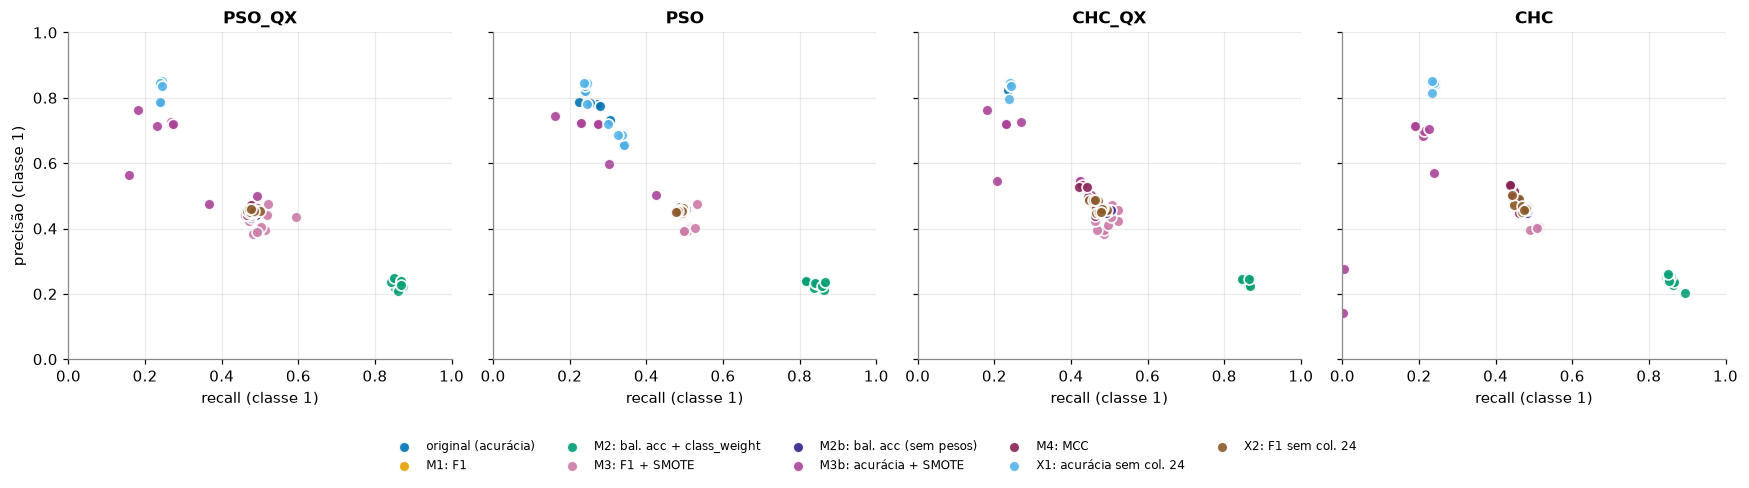

In [14]:
def cor(c): return CORES[c]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9), sharex=True, sharey=True)
for ax, a in zip(axs, ALGS):
    for c in CFGS:
        s = df[(df.algo == a) & (df.config == c)]
        ax.scatter(s.test_recall, s.test_precision, s=50, color=cor(c), edgecolor='white', linewidth=1.2, label=ROTULOS[c], alpha=.9)
    ax.set_title(a); ax.set_xlabel('recall (classe 1)'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axs[0].set_ylabel('precisão (classe 1)')
h, l = axs[0].get_legend_handles_labels(); fig.legend(h, l, loc='lower center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); salvar_fig(fig, 'mel_01_precisao_vs_recall'); plt.show()

### B5.2 Boxplots de F1, acurácia balanceada e recall

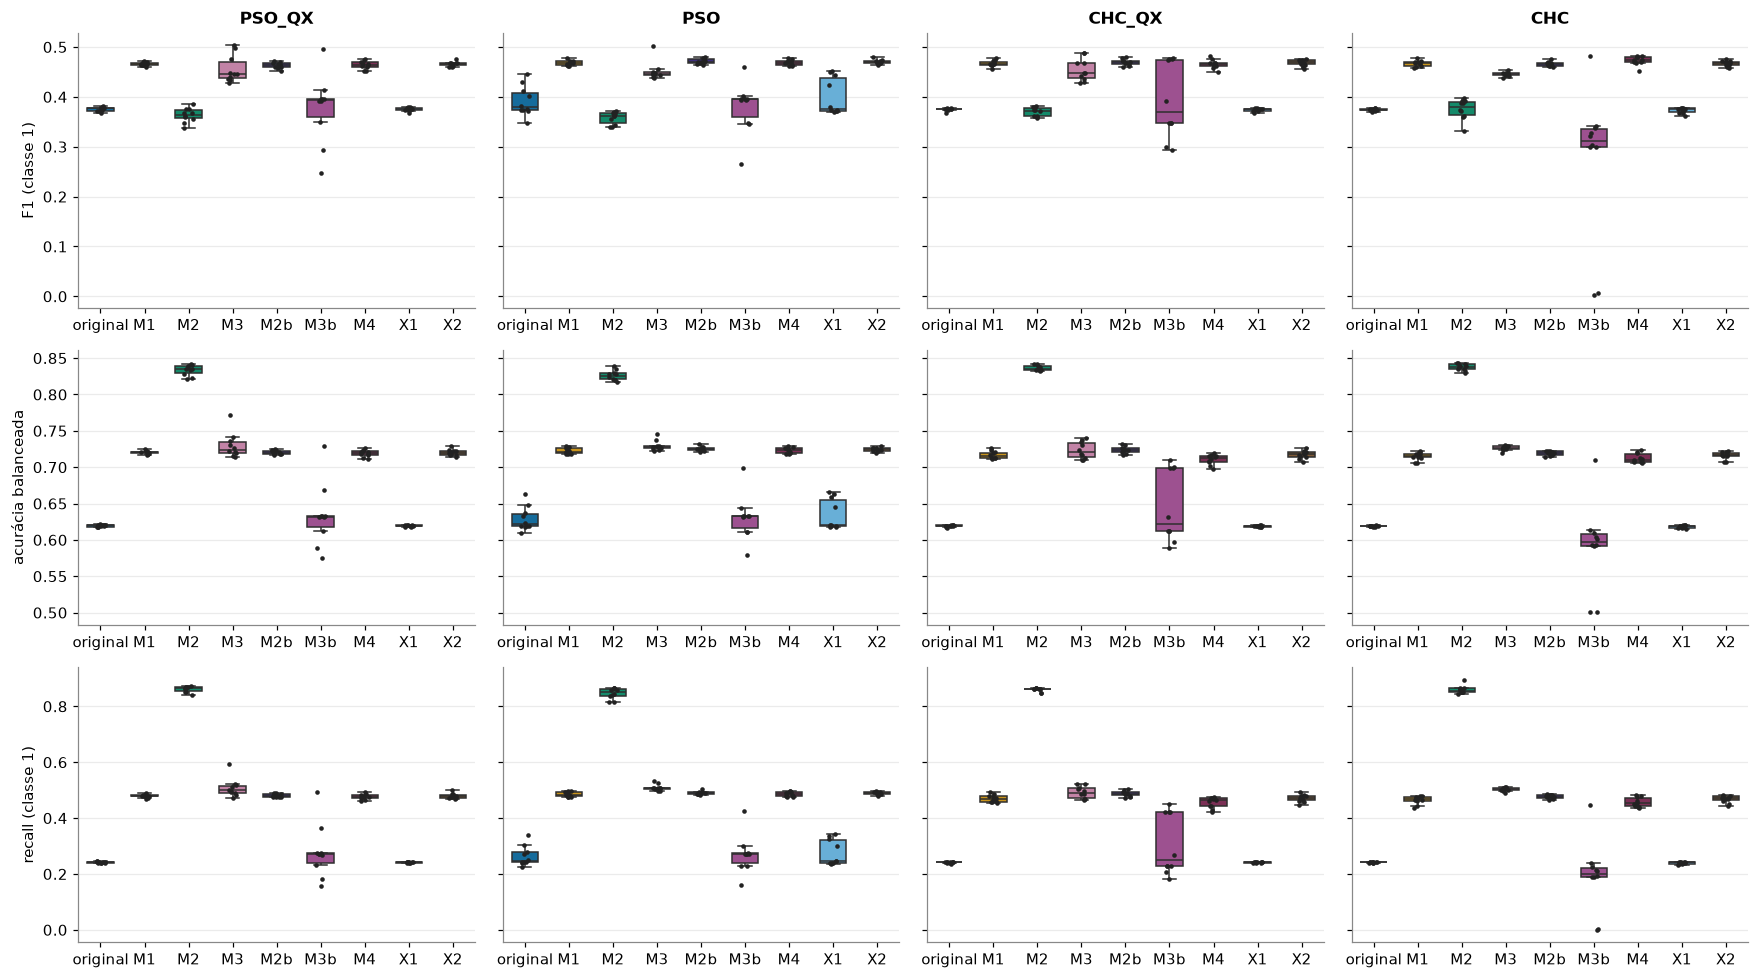

In [15]:
fig, axs = plt.subplots(3, 4, figsize=(16, 9), sharey='row')
for i, (m, nome) in enumerate([('test_f1', 'F1 (classe 1)'), ('test_balanced_accuracy', 'acurácia balanceada'), ('test_recall', 'recall (classe 1)')]):
    for j, a in enumerate(ALGS):
        sub = df[df.algo == a]
        sns.boxplot(data=sub, x='config', y=m, order=CFGS, palette=[cor(c) for c in CFGS], hue='config', hue_order=CFGS, legend=False, ax=axs[i, j], width=.6, fliersize=0)
        sns.stripplot(data=sub, x='config', y=m, order=CFGS, color='#222', size=3, ax=axs[i, j])
        axs[i, j].set_xlabel(''); axs[i, j].set_ylabel(nome if j == 0 else ''); axs[i, j].set_xticks(range(len(CFGS))); axs[i, j].set_xticklabels([c.split('_')[0] for c in CFGS])
        if i == 0: axs[i, j].set_title(a)
plt.tight_layout(); salvar_fig(fig, 'mel_02_boxplots_metricas'); plt.show()

### B5.3 Matrizes de confusão representativas

Para cada configuração mostramos a execução cujo **F1 é o mediano** daquele grupo (a "execução típica"), no conjunto de teste (≈ 39,9 mil instâncias; escolha automática, sem olhar qual é a melhor). Mostramos o PSO_QX (algoritmo-foco); a figura com os quatro algoritmos também é salva em `figures/`. Cada célula traz a contagem e a % da linha (classe real).

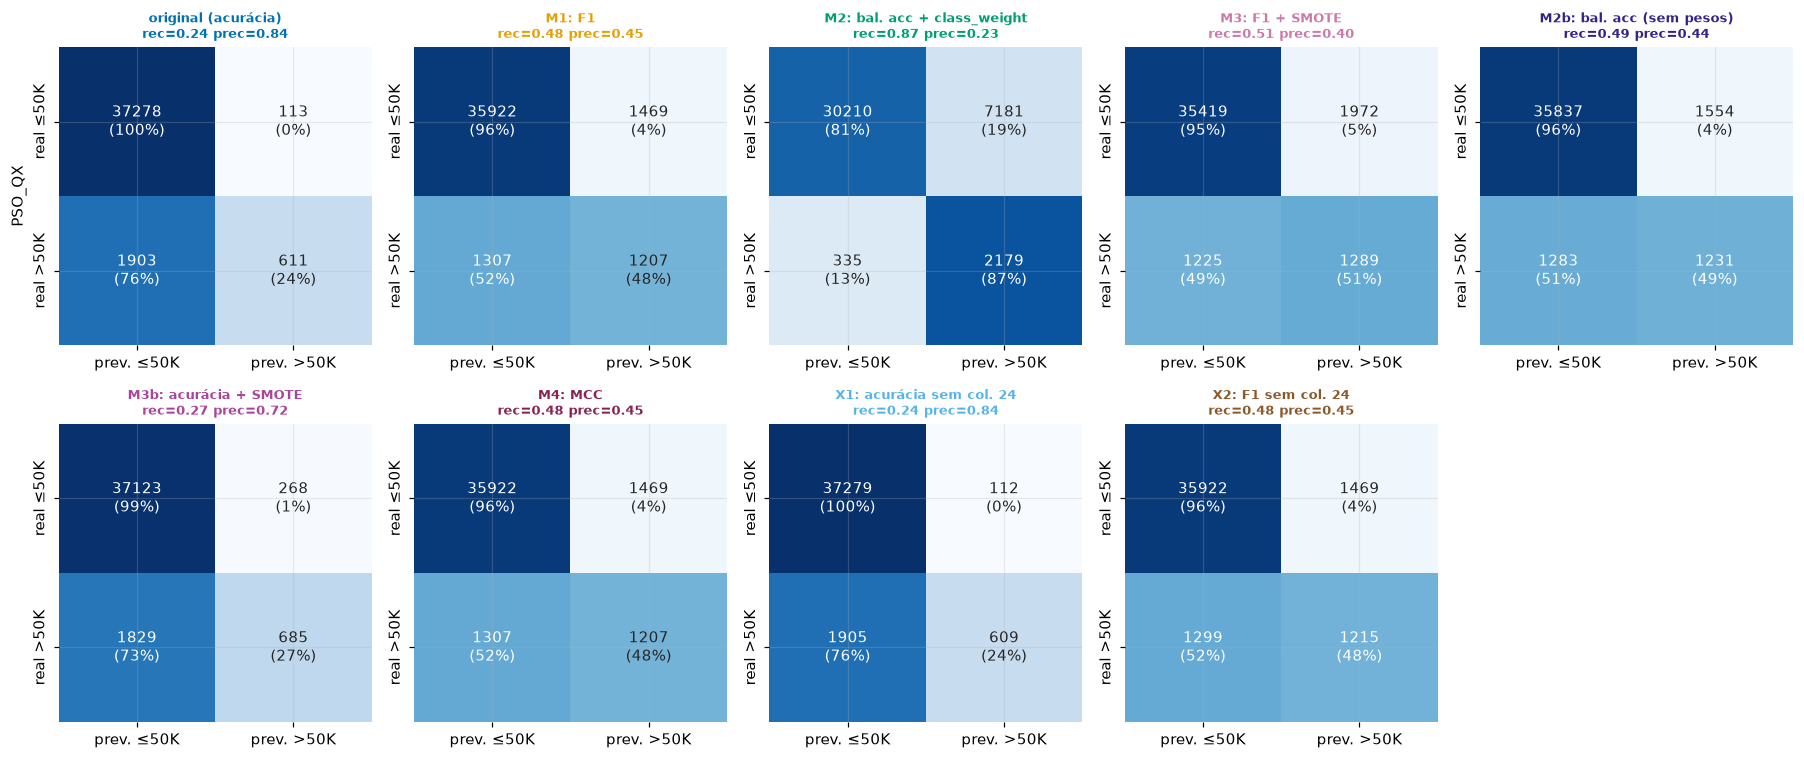

In [16]:
def run_mediana(sub, m='test_f1'):
    sub = sub.sort_values(m).reset_index(drop=True)
    return sub.iloc[len(sub) // 2]

def plot_cm(a, ax_row):
    for ax, c in zip(ax_row, CFGS):
        r = run_mediana(df[(df.algo == a) & (df.config == c)])
        cm = np.array([[r.test_tn, r.test_fp], [r.test_fn, r.test_tp]]); pct = cm / cm.sum(1, keepdims=True) * 100
        sns.heatmap(pct, annot=np.array([[f'{cm[i,j]}\n({pct[i,j]:.0f}%)' for j in range(2)] for i in range(2)]), fmt='', cmap='Blues', vmin=0, vmax=100,
                    cbar=False, ax=ax, xticklabels=['prev. ≤50K', 'prev. >50K'], yticklabels=['real ≤50K', 'real >50K'])
        ax.set_title(f'{ROTULOS[c]}\nrec={r.test_recall:.2f} prec={r.test_precision:.2f}', fontsize=8.5, color=cor(c))
        ax.set_ylabel(a if ax is ax_row[0] else '')
    return None

def grade_cm(a, nome):
    ncol = min(5, len(CFGS)); nlin = -(-len(CFGS) // ncol)
    fig, axs = plt.subplots(nlin, ncol, figsize=(3.3 * ncol, 3.5 * nlin), squeeze=False)
    plot_cm(a, axs.ravel()[:len(CFGS)])
    for ax in axs.ravel()[len(CFGS):]: ax.axis('off')
    plt.tight_layout(); salvar_fig(fig, nome); return fig
grade_cm('PSO_QX', 'mel_03_matrizes_confusao_PSO_QX'); plt.show()
for a in ['PSO', 'CHC_QX', 'CHC']: grade_cm(a, f'mel_03b_matrizes_confusao_{a}'); plt.close('all')

### B5.4 Número de atributos selecionados e tempo

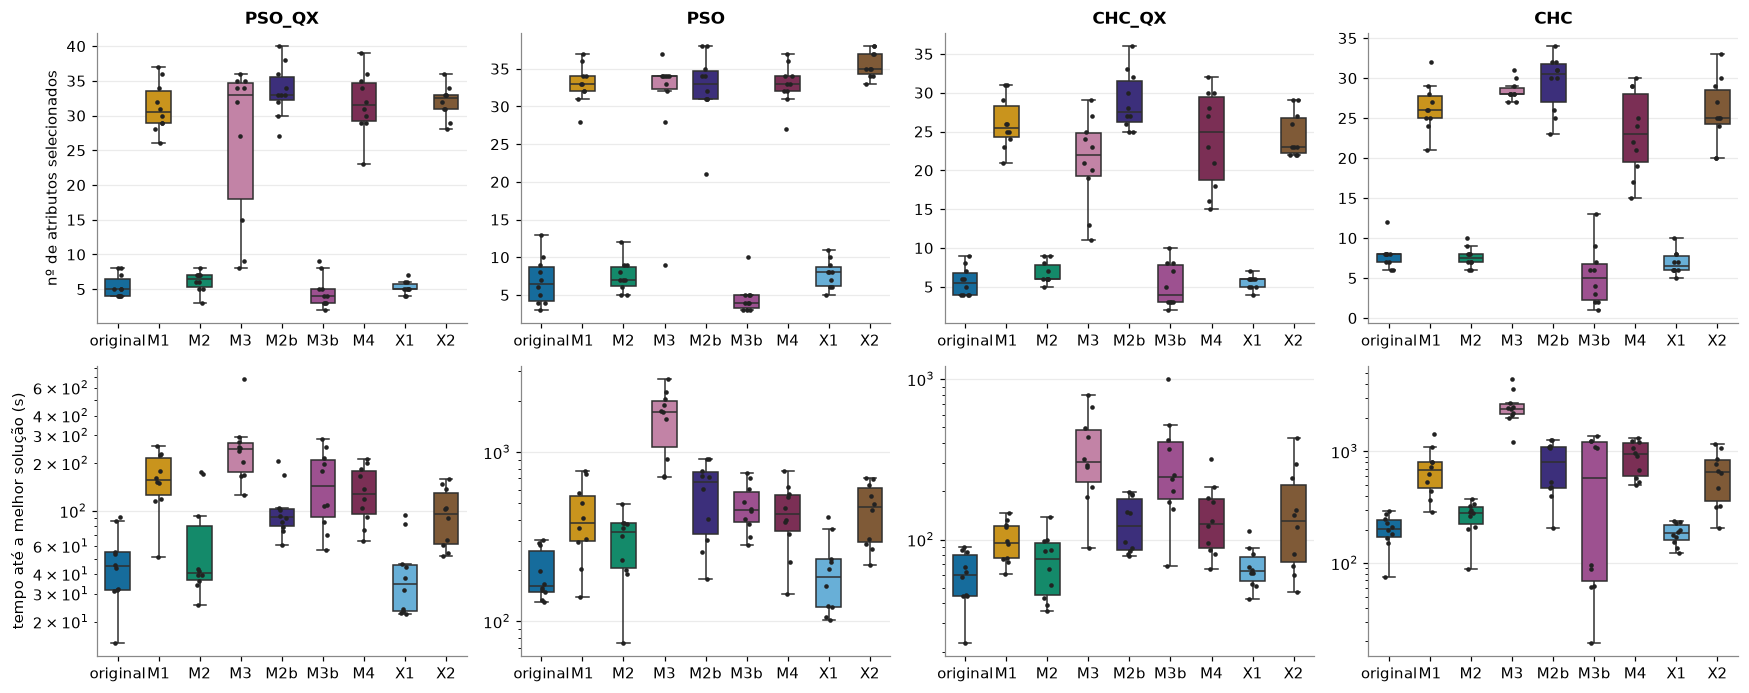

In [17]:
fig, axs = plt.subplots(2, 4, figsize=(16, 6.4))
for j, a in enumerate(ALGS):
    sub = df[df.algo == a]
    for i, (m, nome, log) in enumerate([('n_features', 'nº de atributos selecionados', False), ('time_best', 'tempo até a melhor solução (s)', True)]):
        sns.boxplot(data=sub, x='config', y=m, order=CFGS, palette=[cor(c) for c in CFGS], hue='config', hue_order=CFGS, legend=False, ax=axs[i, j], width=.6, fliersize=0)
        sns.stripplot(data=sub, x='config', y=m, order=CFGS, color='#222', size=3, ax=axs[i, j])
        axs[i, j].set_xlabel(''); axs[i, j].set_ylabel(nome if j == 0 else ''); axs[i, j].set_xticks(range(len(CFGS))); axs[i, j].set_xticklabels([c.split('_')[0] for c in CFGS])
        if log: axs[i, j].set_yscale('log')
        if i == 0: axs[i, j].set_title(a)
plt.tight_layout(); salvar_fig(fig, 'mel_04_atributos_e_tempo'); plt.show()

### B5.5 Quais atributos cada configuração prefere?

Frequência de seleção dos atributos nas soluções finais (todas as execuções de todos os algoritmos de cada configuração). Se a coluna 24 (*instance weight*) aparece muito, o modelo está explorando um atributo que conceitualmente não deveria entrar.

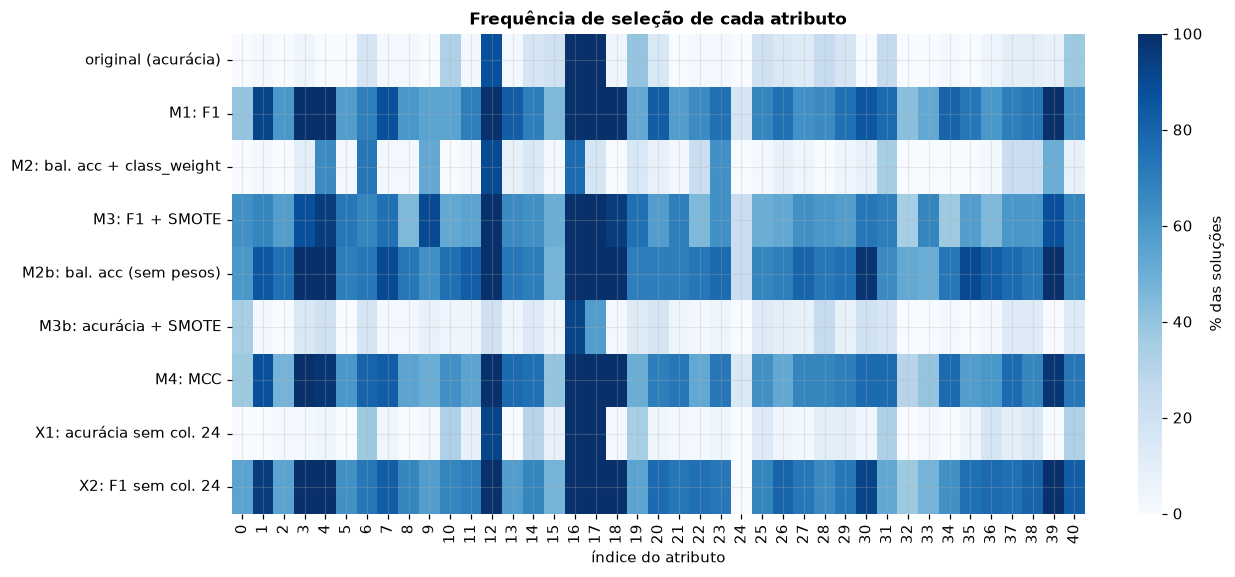

% de soluções que usam a coluna 24 (instance weight): {'original': 0.0, 'M1_f1': 18.0, 'M2_bacc_bal': 0.0, 'M3_f1_smote': 22.0, 'M2b_bacc': 22.0, 'M3b_acc_smote': 0.0, 'M4_mcc': 15.0, 'X1_acc_sem24': 0.0, 'X2_f1_sem24': 0.0}

Estabilidade dos subconjuntos entre sementes (Jaccard médio; 1 = idênticos):


,PSO_QX,PSO,CHC_QX,CHC
original,0.46,0.28,0.45,0.46
M1_f1,0.64,0.71,0.53,0.61
M2_bacc_bal,0.35,0.28,0.45,0.46
M3_f1_smote,0.48,0.61,0.45,0.69
M2b_bacc,0.70,0.69,0.61,0.63
M3b_acc_smote,0.23,0.29,0.27,0.17
M4_mcc,0.67,0.71,0.48,0.56
X1_acc_sem24,0.46,0.34,0.46,0.45
X2_f1_sem24,0.68,0.82,0.52,0.58


In [18]:
freq = pd.DataFrame(0.0, index=CFGS, columns=range(41))
for c in CFGS:
    sub = df[df.config == c]
    for fs in sub.features: freq.loc[c, fs] += 100 / len(sub)
fig, ax = plt.subplots(figsize=(12, 2.2 + .35 * len(CFGS)))
sns.heatmap(freq, cmap='Blues', vmin=0, vmax=100, ax=ax, cbar_kws={'label': '% das soluções'}, yticklabels=[ROTULOS[c] for c in CFGS])
ax.set_xlabel('índice do atributo'); ax.set_title('Frequência de seleção de cada atributo')
plt.tight_layout(); salvar_fig(fig, 'mel_05_frequencia_atributos'); plt.show()
print('% de soluções que usam a coluna 24 (instance weight):', freq[24].round(0).to_dict())

# Estabilidade: similaridade de Jaccard média entre os subconjuntos de sementes diferentes (1 = sempre os mesmos atributos)
from itertools import combinations
def jaccard_medio(listas):
    sets = [set(l) for l in listas]
    v = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
    return np.mean(v) if v else np.nan
estab = pd.DataFrame({a: {c: jaccard_medio(df[(df.algo == a) & (df.config == c)].features) for c in CFGS} for a in ALGS})
print('\nEstabilidade dos subconjuntos entre sementes (Jaccard médio; 1 = idênticos):')
display(estab.round(2))

## B6. Ablações, MCC e o experimento sem a coluna 24

> 🎯 **O que esta seção faz:** Compara as ablações (M2b, M3b), a métrica MCC (M4) e o experimento sem a coluna 24 (X1, X2), com tabelas e testes pareados.
>
> 💡 **Por que existe:** Separar cada ingrediente da melhoria: sem isso não dá para saber *o que* produz o efeito (métrica, pesos, SMOTE ou a coluna 24).

Cada configuração extra responde a uma pergunta específica:

| Pergunta | Comparação | Como ler |
|---|---|---|
| O ganho de M2 vem da **métrica** ou dos **pesos de classe**? | `M2b_bacc` (só métrica) × `M2_bacc_bal` (métrica + pesos) × `original` | Se M2b ≈ original, a métrica sozinha não basta e o ganho vem dos pesos |
| O SMOTE ajuda por si só, ou só junto com o F1? | `M3b_acc_smote` × `original` e `M3_f1_smote` × `M1_f1` | M3b isola o SMOTE sob acurácia |
| F1 ou MCC como fitness? | `M4_mcc` × `M1_f1` | Duas formas de resumir a matriz de confusão |
| A coluna 24 (*instance weight*) estava inflando o resultado? | `X1_acc_sem24` × `original` e `X2_f1_sem24` × `M1_f1` | Se a métrica cai sem ela, a árvore dependia de um atributo que não descreve a pessoa |

As tabelas completas estão em B3 e os testes pareados em B4 (que já incluem esses pares). Abaixo, uma visão compacta das medianas.

In [19]:
alvo = {'test_accuracy': 'acurácia', 'test_recall': 'recall', 'test_precision': 'precisão', 'test_f1': 'F1', 'test_balanced_accuracy': 'acur. balanceada'}
for m, nome in alvo.items():
    piv = df.pivot_table(index='config', columns='algo', values=m, aggfunc='median').reindex(CFGS)[ALGS]
    print(f'--- mediana de {nome} (config × algoritmo) ---')
    display((piv * (100 if m == 'test_accuracy' else 1)).round(3 if m != 'test_accuracy' else 2))

--- mediana de acurácia (config × algoritmo) ---


algo,PSO_QX,PSO,CHC_QX,CHC
config,,,,
original,94.95,94.91,94.93,94.92
M1_f1,93.07,93.05,93.18,93.21
M2_bacc_bal,80.92,81.01,81.67,82.53
M3_f1_smote,92.14,92.07,92.57,92.07
M2b_bacc,92.96,93.07,93.03,93.10
M3b_acc_smote,94.65,94.66,94.33,94.41
M4_mcc,93.05,93.05,93.21,93.65
X1_acc_sem24,94.94,94.87,94.94,94.93
X2_f1_sem24,93.06,93.07,93.17,93.19


--- mediana de recall (config × algoritmo) ---


algo,PSO_QX,PSO,CHC_QX,CHC
config,,,,
original,0.243,0.247,0.242,0.242
M1_f1,0.480,0.481,0.468,0.469
M2_bacc_bal,0.865,0.851,0.863,0.855
M3_f1_smote,0.499,0.507,0.491,0.504
M2b_bacc,0.480,0.488,0.487,0.477
M3b_acc_smote,0.271,0.272,0.249,0.201
M4_mcc,0.476,0.486,0.463,0.452
X1_acc_sem24,0.242,0.245,0.242,0.242
X2_f1_sem24,0.478,0.489,0.472,0.471


--- mediana de precisão (config × algoritmo) ---


algo,PSO_QX,PSO,CHC_QX,CHC
config,,,,
original,0.844,0.786,0.838,0.833
M1_f1,0.452,0.452,0.460,0.462
M2_bacc_bal,0.231,0.230,0.238,0.245
M3_f1_smote,0.401,0.399,0.423,0.398
M2b_bacc,0.446,0.453,0.451,0.455
M3b_acc_smote,0.717,0.720,0.634,0.690
M4_mcc,0.451,0.452,0.462,0.495
X1_acc_sem24,0.841,0.800,0.843,0.843
X2_f1_sem24,0.453,0.453,0.460,0.461


--- mediana de F1 (config × algoritmo) ---


algo,PSO_QX,PSO,CHC_QX,CHC
config,,,,
original,0.377,0.379,0.376,0.375
M1_f1,0.465,0.467,0.466,0.468
M2_bacc_bal,0.364,0.362,0.372,0.381
M3_f1_smote,0.446,0.446,0.449,0.446
M2b_bacc,0.465,0.471,0.469,0.465
M3b_acc_smote,0.394,0.395,0.370,0.312
M4_mcc,0.465,0.469,0.466,0.474
X1_acc_sem24,0.376,0.377,0.376,0.375
X2_f1_sem24,0.467,0.469,0.470,0.469


--- mediana de acur. balanceada (config × algoritmo) ---


algo,PSO_QX,PSO,CHC_QX,CHC
config,,,,
original,0.620,0.622,0.619,0.619
M1_f1,0.720,0.721,0.715,0.716
M2_bacc_bal,0.835,0.826,0.835,0.838
M3_f1_smote,0.724,0.728,0.721,0.727
M2b_bacc,0.720,0.724,0.724,0.720
M3b_acc_smote,0.632,0.632,0.621,0.598
M4_mcc,0.719,0.724,0.713,0.710
X1_acc_sem24,0.620,0.621,0.619,0.619
X2_f1_sem24,0.720,0.725,0.718,0.717


In [20]:
print('Atributos usados com mais frequência por configuração (índice: % das soluções) — veja se a coluna 24 aparece:')
for c in CFGS:
    top = freq.loc[c].sort_values(ascending=False).head(6)
    print(f'  {c:14s}', {int(k): int(round(v)) for k, v in top.items()})

Atributos usados com mais frequência por configuração (índice: % das soluções) — veja se a coluna 24 aparece:
  original       {17: 100, 16: 100, 12: 88, 19: 40, 40: 38, 10: 32}
  M1_f1          {12: 100, 39: 100, 3: 100, 4: 100, 18: 100, 17: 100}
  M2_bacc_bal    {12: 90, 16: 78, 6: 72, 4: 65, 23: 62, 9: 52}
  M3_f1_smote    {16: 100, 12: 100, 17: 100, 4: 95, 18: 95, 9: 90}
  M2b_bacc       {16: 100, 39: 100, 3: 100, 4: 100, 18: 100, 17: 100}
  M3b_acc_smote  {16: 92, 17: 58, 0: 35, 28: 25, 12: 20, 30: 20}
  M4_mcc         {16: 100, 3: 100, 18: 100, 12: 100, 17: 100, 39: 98}
  X1_acc_sem24   {17: 100, 16: 100, 12: 92, 6: 38, 19: 35, 40: 32}
  X2_f1_sem24    {16: 100, 39: 100, 3: 100, 4: 100, 18: 100, 12: 100}


## B7. Transferência: os subconjuntos escolhidos servem para outros classificadores?

> 🎯 **O que esta seção faz:** Pega os subconjuntos de atributos já escolhidos (com árvore) e os avalia com Regressão Logística e Random Forest, sem nova busca.
>
> 💡 **Por que existe:** Verifica se a seleção "generaliza": se os atributos escolhidos pela fitness nova também são melhores para outros modelos, a melhoria é sobre os *atributos*, não um artefato da árvore.

A busca usa **sempre** uma árvore de decisão. Mas se um subconjunto de atributos é realmente bom, ele deveria ajudar outros modelos também. Então pegamos o subconjunto final de cada execução e treinamos, **no treino original (sem SMOTE e sem pesos da árvore)**:

* **Regressão Logística** (`class_weight='balanced'`) — modelo linear;
* **Random Forest** (30 árvores, `class_weight='balanced_subsample'`) — conjunto de árvores.

Medimos no **teste**: **ROC-AUC** e **PR-AUC** (não dependem de limiar; a PR-AUC é a mais informativa com classes desbalanceadas), além de recall e F1 no limiar 0,5. Ficam como referência os mesmos modelos com **todos os 41 atributos**. Nenhuma busca é refeita; só se treina um modelo por subconjunto.

0 avaliações de transferência pendentes (de 360).


Referência (41 atributos): {'LR': {'roc_auc': 0.929, 'pr_auc': 0.548, 'recall': 0.883, 'f1': 0.385}, 'RF': {'roc_auc': 0.941, 'pr_auc': 0.618, 'recall': 0.717, 'f1': 0.56}}


,LR_pr_auc,LR_roc_auc,LR_recall,LR_f1,RF_pr_auc,RF_roc_auc,RF_recall,RF_f1
config,,,,,,,,
original,0.345,0.799,0.805,0.261,0.406,0.872,0.799,0.329
M1_f1,0.536,0.925,0.881,0.379,0.615,0.941,0.762,0.534
M2_bacc_bal,0.352,0.855,0.856,0.277,0.519,0.918,0.869,0.376
M3_f1_smote,0.542,0.927,0.882,0.384,0.617,0.942,0.749,0.548
M2b_bacc,0.542,0.927,0.881,0.382,0.618,0.942,0.753,0.545
M3b_acc_smote,0.270,0.749,0.545,0.266,0.354,0.835,0.820,0.325
M4_mcc,0.534,0.925,0.881,0.380,0.613,0.941,0.767,0.533
X1_acc_sem24,0.340,0.799,0.794,0.264,0.396,0.857,0.793,0.323
X2_f1_sem24,0.542,0.926,0.880,0.383,0.615,0.942,0.759,0.543


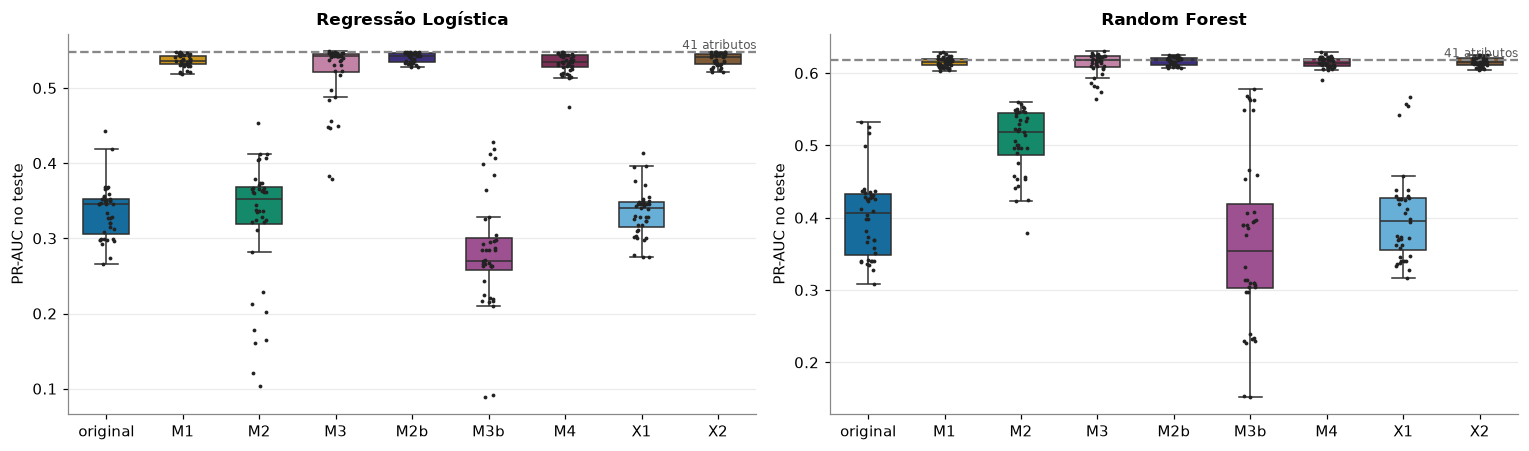

In [21]:
transf = runner.transferencia_todas(df, n_jobs=N_JOBS, executar=EXECUTAR_TRANSF)
transf = transf[transf.config.isin(CFGS)]
# referência: todos os 41 atributos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, recall_score, f1_score
dsb = runner._dataset_base(); ref = {}
for nome, m in {'LR': LogisticRegression(max_iter=300, class_weight='balanced'),
                'RF': RandomForestClassifier(n_estimators=30, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=N_JOBS, random_state=0)}.items():
    m.fit(dsb.X_train, dsb.y_train); p = m.predict_proba(dsb.X_test)[:, 1]
    ref[nome] = dict(roc_auc=roc_auc_score(dsb.y_test, p), pr_auc=average_precision_score(dsb.y_test, p),
                     recall=recall_score(dsb.y_test, p >= .5), f1=f1_score(dsb.y_test, p >= .5))
print('Referência (41 atributos):', {k: {m: round(v, 3) for m, v in d.items()} for k, d in ref.items()})
tab = transf.groupby('config')[[f'{m}_{k}' for m in ('LR', 'RF') for k in ('pr_auc', 'roc_auc', 'recall', 'f1')]].median().reindex(CFGS).round(3)
display(tab)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharey=False)
for ax, m in zip(axs, ['LR', 'RF']):
    sns.boxplot(data=transf, x='config', y=f'{m}_pr_auc', order=CFGS, hue='config', hue_order=CFGS, palette=[CORES[c] for c in CFGS], legend=False, ax=ax, width=.6, fliersize=0)
    sns.stripplot(data=transf, x='config', y=f'{m}_pr_auc', order=CFGS, color='#222', size=2.5, ax=ax)
    ax.axhline(ref[m]['pr_auc'], ls='--', c='#888'); ax.text(len(CFGS) - .5, ref[m]['pr_auc'], ' 41 atributos', va='bottom', ha='right', fontsize=8, color='#555')
    ax.set_title({'LR': 'Regressão Logística', 'RF': 'Random Forest'}[m]); ax.set_xlabel(''); ax.set_ylabel('PR-AUC no teste')
    ax.set_xticks(range(len(CFGS))); ax.set_xticklabels([c.split('_')[0] for c in CFGS])
plt.tight_layout(); salvar_fig(fig, 'mel_06_transferencia_pr_auc'); plt.show()

## B8. Discussão: o trade-off e a recomendação

> 🎯 **O que esta seção faz:** Interpreta o trade-off e recomenda quando usar cada configuração.
>
> 💡 **Por que existe:** É a conclusão do trabalho: números sem interpretação não sustentam uma recomendação.

Os números abaixo são calculados automaticamente a partir dos resultados (mediana das execuções, no teste).

In [22]:
def med(a, c, m): return df[(df.algo == a) & (df.config == c)][m].median()
for a in ALGS:
    print(f'--- {a} ---')
    for c in [c for c in CFGS if c != 'original']:
        print(f'  {c:13s} acurácia {100*med(a,"original","test_accuracy"):.2f}% → {100*med(a,c,"test_accuracy"):.2f}% | '
              f'recall {med(a,"original","test_recall"):.2f} → {med(a,c,"test_recall"):.2f} | '
              f'precisão {med(a,"original","test_precision"):.2f} → {med(a,c,"test_precision"):.2f} | '
              f'F1 {med(a,"original","test_f1"):.3f} → {med(a,c,"test_f1"):.3f} | '
              f'acc.bal. {med(a,"original","test_balanced_accuracy"):.3f} → {med(a,c,"test_balanced_accuracy"):.3f}')
print('\nReferência: classe majoritária = 93,70% de acurácia, recall 0, acurácia balanceada 0,50.')

--- PSO_QX ---
  M1_f1         acurácia 94.95% → 93.07% | recall 0.24 → 0.48 | precisão 0.84 → 0.45 | F1 0.377 → 0.465 | acc.bal. 0.620 → 0.720
  M2_bacc_bal   acurácia 94.95% → 80.92% | recall 0.24 → 0.87 | precisão 0.84 → 0.23 | F1 0.377 → 0.364 | acc.bal. 0.620 → 0.835
  M3_f1_smote   acurácia 94.95% → 92.14% | recall 0.24 → 0.50 | precisão 0.84 → 0.40 | F1 0.377 → 0.446 | acc.bal. 0.620 → 0.724
  M2b_bacc      acurácia 94.95% → 92.96% | recall 0.24 → 0.48 | precisão 0.84 → 0.45 | F1 0.377 → 0.465 | acc.bal. 0.620 → 0.720
  M3b_acc_smote acurácia 94.95% → 94.65% | recall 0.24 → 0.27 | precisão 0.84 → 0.72 | F1 0.377 → 0.394 | acc.bal. 0.620 → 0.632
  M4_mcc        acurácia 94.95% → 93.05% | recall 0.24 → 0.48 | precisão 0.84 → 0.45 | F1 0.377 → 0.465 | acc.bal. 0.620 → 0.719
  X1_acc_sem24  acurácia 94.95% → 94.94% | recall 0.24 → 0.24 | precisão 0.84 → 0.84 | F1 0.377 → 0.376 | acc.bal. 0.620 → 0.620
  X2_f1_sem24   acurácia 94.95% → 93.06% | recall 0.24 → 0.48 | precisão 0.84 → 0.

**Leitura dos resultados** *(10 sementes por algoritmo e configuração, 360 execuções; medianas no teste. Os testes de Wilcoxon pareados por semente têm n = 10, então o menor p possível é ≈ 0,002 — vários resultados "*" abaixo estão nesse piso.)*

1. **A acurácia cai em todas as configurações que trocam a fitness — e isso é esperado.** O original (≈ 94,9 %) otimiza exatamente a acurácia; M1 e M4 ficam em ≈ 93,0–93,2 %, M3 em ≈ 92,1–92,6 % e M2 em ≈ 81–82 %. M1, M3 e M4 ficam *abaixo* do classificador majoritário (93,7 %), o que só preocupa se o objetivo for acertar o máximo de pessoas; aqui o objetivo é encontrar quem tem renda alta.
2. **M1 (F1) é o melhor equilíbrio.** Nos quatro algoritmos, o recall sobe de ≈ 0,24 para ≈ 0,47–0,48 (Δ ≈ +0,23, p ≈ 0,002 em todos), o F1 de ≈ 0,376 para ≈ 0,466 (Δ ≈ +0,09, p ≈ 0,002) e a acurácia balanceada de ≈ 0,62 para ≈ 0,72 (p ≈ 0,002). A precisão cai de ≈ 0,79–0,84 para ≈ 0,45–0,46. **O MCC, porém, não melhora**: fica em ≈ 0,43 (Δ entre −0,009 e 0, p ≥ 0,08) — o ganho de recall é pago, quase na mesma medida, com perda de precisão. O F1 fica acima do da árvore com os 41 atributos (≈ 0,45), sem alterar o classificador.
3. **M2 (acur. balanceada + `class_weight`) vai ao extremo do recall.** Recall ≈ 0,85–0,87 e acurácia balanceada ≈ 0,84 (a maior de todas), mas a precisão cai para ≈ 0,23–0,25 e o MCC cai (≈ 0,38–0,40, p ≈ 0,002 em todos). O F1 (≈ 0,36–0,38) fica **próximo do original**: menor nos PSO (Δ ≈ −0,013 a −0,017, p < 0,02), sem diferença significativa nos CHC. A ablação **M2b** (mesma acurácia balanceada **sem** `class_weight`) cai no mesmo ponto de M1 (recall ≈ 0,48, F1 ≈ 0,47): o comportamento extremo de M2 vem do **`class_weight`**, não da métrica (F1 de M2b − M2 ≈ +0,08 a +0,11, p ≈ 0,002 nos 4). Faz sentido quando **perder um positivo custa muito mais que um alarme falso**.
4. **M3 (F1 + SMOTE) não compensou.** Recall um pouco maior que o de M1 (≈ 0,50 contra ≈ 0,48; p < 0,03 nos 4), mas F1 e MCC menores nos quatro algoritmos (F1 ≈ 0,446 contra ≈ 0,466; Δ ≈ −0,02; significativo no CHC, p ≈ 0,002, e no PSO pelo teste *t*, mas não no CHC_QX e PSO_QX, p ≈ 0,08–0,38), acurácia menor e custo de tempo ≈ 3,5× (≈ 3.100–3.350 s contra ≈ 860 s nos puros). **M3b** (acurácia + SMOTE) **não ajuda e é instável**: recall e F1 sem ganho significativo no PSO/QX (p ≥ 0,27), *piores* no CHC (F1 −0,06, p ≈ 0,049) e com execuções degeneradas (no CHC, 2 de 10 execuções acertaram a maioria mas encontraram ≈ 0 % dos positivos). O SMOTE sozinho não faz a busca olhar para a classe rara; quem faz isso é a métrica.
5. **MCC (M4) ≈ F1 (M1).** Recall e F1 de M4 não diferem de M1 de forma significativa (recall p ≥ 0,09; F1 p ≥ 0,06). Note que otimizar o MCC **não aumentou o MCC** em relação ao original (≈ 0,43 nos dois; Δ entre −0,009 e +0,008): a base tem um ótimo de MCC já alcançado pela acurácia, o que reforça que MCC e F1 medem trade-offs diferentes — o MCC "não enxerga" o ganho de recall que o F1 enxerga. Para encontrar a classe rara, F1 é a escolha mais simples de explicar.
6. **A coluna 24 (instance weight) não muda nada.** Removê-la (X1, X2) deixa acurácia, recall e F1 iguais aos de `original` e M1 (recall e F1: p ≥ 0,37; Δ ≈ 0). A busca não dependia dela.
7. **O ganho de tempo do QX se mantém.** Tempo total mediano por execução (inclui carga dos dados e reavaliação final; medido com 8 processos em paralelo, então vale como ordem de grandeza): original ≈ 70–75 s (QX) contra ≈ 230–270 s (puros); com F1 ≈ 210–280 s (QX) contra ≈ 860 s (puros). Pelo tempo até a melhor solução (`time_best`), o ganho é ≈ 3,4–3,6× no original e ≈ 2,4–7× com F1. O custo absoluto do F1 é maior que o da acurácia (≈ 3–4× nos QX).
8. **Os subconjuntos mudam.** O original escolhe poucos atributos (5–8); com F1/MCC a busca prefere ≈ 23–35; com M2 ≈ 6–7; com acurácia + SMOTE ≈ 4–5. Ver figuras B5.4/B5.5.
9. **Transferência (B7).** Treinando LR e RF no treino original só com os atributos escolhidos, os subconjuntos de F1/MCC/M2b/M3 dão PR-AUC ≈ 0,53–0,54 (LR) e ≈ 0,61–0,62 (RF) contra ≈ 0,35 e ≈ 0,41 dos subconjuntos do original; ROC-AUC ≈ 0,925–0,942 contra ≈ 0,80–0,87. Ou seja, os subconjuntos maiores não servem só à árvore: carregam informação útil a outros modelos. Os do original (6 atributos) e os de M3b (4) são os piores; M2 (7 atributos) fica no meio.

**Quando usar cada configuração**

| Situação | Recomendação |
|---|---|
| Classes balanceadas, ou acurácia é de fato o objetivo | `original` |
| Compromisso entre achar positivos e não gerar alarmes falsos demais (caso geral) | **M1 (F1)** — M4 (MCC) e M2b equivalem |
| Perder um positivo é muito mais caro que um alarme falso | M2 (acur. balanceada + `class_weight`) |
| Interesse em aumento de dados | M3 — sem vantagem clara e ≈ 3,5× mais lento |

**Recomendação final:** usar **M1 (F1 como fitness)** como substituto direto da acurácia: troca de uma linha, recall dobra, F1 e acurácia balanceada sobem, o ganho do QX permanece. O custo é tempo e subconjuntos maiores (≈ 25–33 atributos em vez de 5–8).

**Limitações da melhoria (para o relatório)**

* A divisão 60/20/20 é **uma só** e sequencial (sem validação cruzada); a variabilidade vem apenas das sementes das buscas.
* A fitness é calculada na validação e a melhor solução é escolhida nela — há alguma tendência de *overfitting* à validação (por isso o teste só é usado no fim).
* Árvore de decisão totalmente crescida com limiar fixo (0,5): outros classificadores ou ajuste do limiar poderiam mudar o trade-off.
* O trade-off precisão × recall é uma escolha de **negócio**, não estatística; mostramos os dois lados.
* Com n = 10, o teste de Wilcoxon tem piso de p ≈ 0,002; diferenças pequenas (como M1 × M3 em F1) não são detectáveis com tão poucas sementes.
* Os tempos foram medidos com 8 processos simultâneos numa máquina de 10 núcleos; servem como ordem de grandeza, não como *benchmark* isolado.
* A baseline (árvore com 41 atributos) dá 92,815 % aqui contra 92,87 % do artigo; a causa não foi identificada.

In [23]:
RES_DIR.mkdir(exist_ok=True)
saida = df.copy(); saida['features'] = saida['features'].apply(lambda f: ' '.join(map(str, f)))
saida.to_csv(RES_DIR / 'melhoria_runs.csv', index=False)
resumo.reset_index().to_csv(RES_DIR / 'melhoria_resumo.csv', index=False)
testes.to_csv(RES_DIR / 'melhoria_testes_estatisticos.csv', index=False)
transf.to_csv(RES_DIR / 'melhoria_transferencia.csv', index=False)
print('salvos: results/melhoria_runs.csv, melhoria_resumo.csv, melhoria_testes_estatisticos.csv | figuras em figures/')

salvos: results/melhoria_runs.csv, melhoria_resumo.csv, melhoria_testes_estatisticos.csv | figuras em figures/


---
# PARTE C — Resumo para o relatório

> 🎯 **O que esta seção faz:** responde, item a item, ao roteiro da disciplina.
> 💡 **Por que existe:** o grupo pode copiar daqui para o relatório e os slides.

* **Descrição da base:** census-income (UCI Census-Income KDD) — 199.523 instâncias × 41 atributos numéricos já codificados + rótulo binário (renda > 50K), sem valores faltantes. **Desbalanceada: 93,79 % classe 0 e 6,21 % classe 1.** A coluna 24 é o *instance weight* (não deveria ser atributo de entrada; o código a usa como atributo).
* **Tamanho da população:** 50 indivíduos (CHC) / 50 partículas (PSO), nos quatro algoritmos. Meta-modelo QX: `q = 10`, controle de evolução a cada `f = 10` gerações, `f_no_change = 2`.
* **% treino/validação/teste:** 60 % / 20 % / 20 %, **sequencial, sem embaralhar** (`shuffle=False`), normalização *z-score* ajustada só no treino. Fitness na validação; teste só na avaliação final. (SMOTE, em M3, só no treino.)
* **Validação cruzada:** **não é usada.** O artigo usa *holdout* 60/20/20; a robustez estatística vem de **repetições independentes** (sementes 0 a N−1; artigo: 10) dos algoritmos estocásticos, com mediana ± desvio padrão. Na Parte B, os testes de Wilcoxon e *t* são pareados por semente.
* **Algoritmos:** CHC_QX, PSO_QX, CHC e PSO — seleção de atributos *wrapper* com Árvore de Decisão (`random_state=0`).
* **Critério dos hiperparâmetros:** valores do artigo/notebook oficial, **sem *Grid Search***. Divergências conhecidas entre artigo e código (q = 20 vs 10; tempo de CPU do CHC; embaralhamento) foram documentadas e mantivemos o que o código faz. As métricas de fitness da melhoria foram escolhidas por justificativa (B2), nunca pelo desempenho no teste.
* **Transfer learning / *dropout*:** **não se aplicam** — não há rede neural nem pré-treinamento; base tabular e modelo de árvore de decisão.
* **Aumento de dados:** não faz parte do artigo; aparece apenas em M3 (SMOTE no treino), como alternativa de tratamento do desbalanceamento.
* **Desbalanceamento:** o original **não trata** (a acurácia esconde um recall ≈ 0,24); a melhoria **trata**, trocando a fitness por F1 (M1) ou acurácia balanceada com `class_weight` (M2), ou aumentando os dados (M3).
* **Métricas:** acurácia (a do artigo), acurácia balanceada, precisão, recall e F1 da classe 1, MCC, ROC-AUC, matriz de confusão, nº de atributos e tempo até a melhor solução.
* **Resultado da replicação:** ver Tabela da seção A7 (nossa mediana × artigo, Δ em pp).
* **Resultado da melhoria:** ver tabela B3 e testes B4; ablações em B6, transferência em B7; recomendação em B8 (M1 como padrão; M2 se recall for prioritário). Com 10 sementes: recall ≈ 0,24 → ≈ 0,48 e F1 ≈ 0,376 → ≈ 0,466 com M1, ao custo de ≈ 1,8 pp de acurácia; M2 chega a recall ≈ 0,86 com precisão ≈ 0,24; M3 (SMOTE) é ≈ 3,5× mais lento sem ganho de F1; a coluna 24 não altera nada.